# Import necessary packages

In [1]:
from itertools import combinations
import os

import matplotlib.pyplot as plt
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = ['Arial']
import nibabel as nib
import numpy as np
import pandas as pd
from scipy import ndimage, stats
from scipy.stats import t
from scipy.optimize import curve_fit, fsolve


# Global variables

In [2]:
PROJECT_DIR = 'data_paper'


# Plot CTDIvol vs. NI

a = 605.72 [594.43, 617.22]
b = -2.23 [-2.24, -2.22]


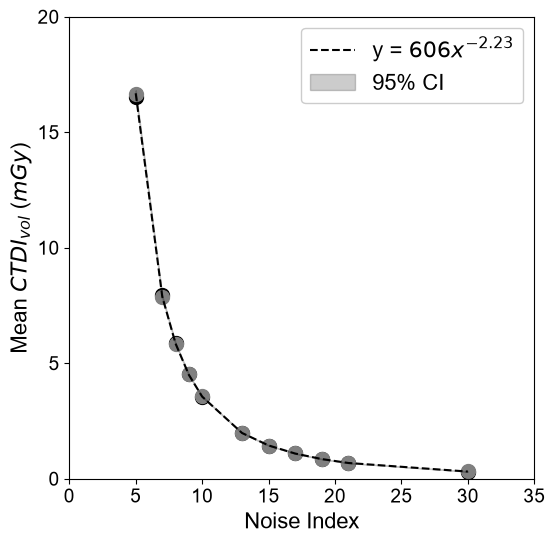

In [3]:
def linear_power_fit(x, y):
    popt_log, pcov_log = curve_fit(lambda x, b, ln_a: b * x + ln_a, np.log(x), np.log(y))
    b_fit, ln_a_fit = popt_log[0], popt_log[1]
    a_fit = np.exp(ln_a_fit)
    return a_fit, b_fit, ln_a_fit, pcov_log

def power_law(x, a, b):
    return a*(x**b)


all_CTDIvol_values = {
    'NI = 5':       16.53,
    'NI = 5 COPY':  16.64,
    'NI = 7':       7.93,
    'NI = 7 COPY':  7.88,
    'NI = 8':       5.86,
    'NI = 8 COPY':  5.83,
    'NI = 9':       4.53,
    'NI = 9 COPY':  4.51,
    'NI = 10':      3.53,
    'NI = 10 COPY': 3.57,
    'NI = 13':      1.98,
    'NI = 13 COPY': 1.97,
    'NI = 15':      1.43,
    'NI = 15 COPY': 1.43,
    'NI = 17':      1.09,
    'NI = 17 COPY': 1.09,
    'NI = 19':      0.84,
    'NI = 19 COPY': 0.84,
    'NI = 21':      0.69,
    'NI = 21 COPY': 0.68,
    'NI = 30':      0.30,
    'NI = 30 COPY': 0.31,
}

plt.figure(figsize=(6,6))
ax = plt.gca()
ax.tick_params(axis='x', labelsize=14)
ax.tick_params(axis='y', labelsize=14)

temp_x_data = []
temp_y_data = []
for temp_key,temp_value in all_CTDIvol_values.items():
    temp_NI = int(temp_key.split(' = ')[1].split(' ')[0])
    temp_x_data.append(temp_NI)
    temp_y_data.append(temp_value)
    if 'COPY' in temp_key:
        plt.scatter(temp_NI, temp_value, s=100, color='grey')
    else:
        plt.scatter(temp_NI, temp_value, s=100, color='k')

sorted_data = sorted([(temp_x_data[i], temp_y_data[i]) for i in range(len(temp_x_data))], key=lambda d:d[0])
temp_x_data = [d[0] for d in sorted_data]
temp_y_data = [d[1] for d in sorted_data]
popt, pcov = curve_fit(power_law, temp_x_data, temp_y_data, p0=[sorted(temp_y_data)[0],-1])
y_pred = power_law(temp_x_data, *popt)

# Fitting
a_fit, b_fit, ln_a_fit, pcov_log = linear_power_fit(temp_x_data, temp_y_data)
CTDIVOL_FIT = (a_fit, b_fit)
plt.plot(temp_x_data, a_fit*(temp_x_data**b_fit), linestyle='--', color='k', label=f'y = ${a_fit:.0f}x^{{{b_fit:.2f}}}$')
# 95% CI
n = len(temp_x_data)
dof = n-2
t_val = t.ppf(0.975, dof)
log_y_pred = b_fit * np.log(temp_x_data) + ln_a_fit
residuals = np.log(temp_y_data) - log_y_pred
s_err = np.sqrt(np.sum(residuals**2) / dof)
log_x_mean = np.mean(np.log(temp_x_data))
s_fit_log = s_err * np.sqrt(1/n + (np.log(temp_x_data) - log_x_mean)**2 / np.sum((np.log(temp_x_data) - log_x_mean)**2))
log_y_ci_lower = (b_fit * np.log(temp_x_data) + ln_a_fit) - t_val * s_fit_log
log_y_ci_upper = (b_fit * np.log(temp_x_data) + ln_a_fit) + t_val * s_fit_log
plt.fill_between(temp_x_data, np.exp(log_y_ci_lower), np.exp(log_y_ci_upper), color='k', alpha=0.2, label='95% CI')
se_b, se_ln_a = np.sqrt(np.diag(pcov_log))
b_ci_lower, b_ci_upper = b_fit - t_val * se_b, b_fit + t_val * se_b
ln_a_ci_lower, ln_a_ci_upper = ln_a_fit - t_val * se_ln_a, ln_a_fit + t_val * se_ln_a
a_ci_lower, a_ci_upper = np.exp(ln_a_ci_lower), np.exp(ln_a_ci_upper)
print(f'a = {a_fit:.2f} [{a_ci_lower:.2f}, {a_ci_upper:.2f}]')
print(f'b = {b_fit:.2f} [{b_ci_lower:.2f}, {b_ci_upper:.2f}]')

ax = plt.gca()
ax.set_yticks([0,5,10,15,20])
plt.xlim([0,35])
plt.ylim([0,20])
plt.xlabel('Noise Index', fontsize=16)
plt.ylabel(r'Mean $CTDI_{vol}$ ($mGy$)', fontsize=16)
plt.legend(loc='upper right', framealpha=1, fontsize=16)
plt.show()


# Determine the average tube current for each NI setting

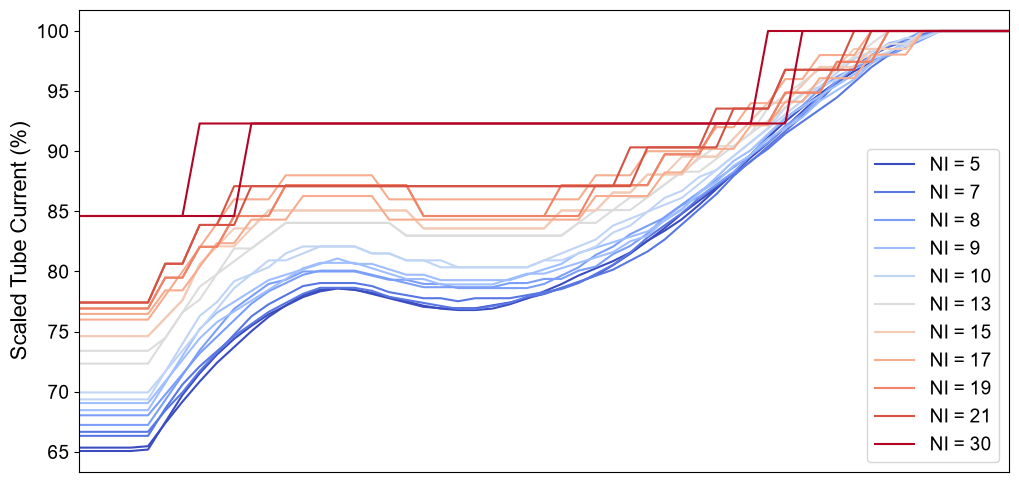

NI = 5: 689.7181818181818 [545.5,836.5]
NI = 7: 328.07272727272726 [264.0,397.0]
NI = 8: 242.85454545454547 [196.5,290.5]
NI = 9: 186.89090909090908 [153.0,222.5]
NI = 10: 147.0090909090909 [120.5,173.0]
NI = 13: 81.52727272727273 [68.5,94.0]
NI = 15: 58.68181818181818 [50.0,67.0]
NI = 17: 44.67272727272727 [38.5,50.5]
NI = 19: 34.54545454545455 [30.0,39.0]
NI = 21: 27.763636363636362 [24.0,31.0]
NI = 30: 12.1 [11.0,13.0]

NI = 5: 0.14%
NI = 7: 0.18%
NI = 8: 0.28%
NI = 9: 0.19%
NI = 10: 0.19%
NI = 13: 0.21%
NI = 15: 0.05%
NI = 17: 0.33%
NI = 19: 0.05%
NI = 21: 0.13%
NI = 30: 0.38%


In [4]:
all_tube_currents = {
    5: {
        'series_1': [547.0, 547.0, 547.0, 547.0, 548.0, 564.0, 579.0, 593.0, 606.0, 617.0, 628.0, 638.0, 646.0, 653.0, 657.0, 658.0, 657.0, 654.0, 651.0, 648.0, 645.0, 644.0, 644.0, 644.0, 646.0, 648.0, 651.0, 654.0, 658.0, 662.0, 667.0, 674.0, 682.0, 691.0, 698.0, 706.0, 716.0, 727.0, 738.0, 749.0, 759.0, 770.0, 781.0, 792.0, 801.0, 809.0, 815.0, 821.0, 829.0, 834.0, 837.0, 837.0, 837.0, 837.0, 837.0],
        'series_2': [544.0, 544.0, 544.0, 544.0, 545.0, 564.0, 583.0, 598.0, 611.0, 622.0, 631.0, 639.0, 645.0, 651.0, 655.0, 657.0, 656.0, 654.0, 651.0, 648.0, 645.0, 643.0, 642.0, 642.0, 643.0, 646.0, 650.0, 655.0, 660.0, 666.0, 671.0, 676.0, 682.0, 690.0, 699.0, 709.0, 718.0, 727.0, 737.0, 750.0, 762.0, 773.0, 783.0, 792.0, 801.0, 811.0, 819.0, 825.0, 829.0, 832.0, 836.0, 836.0, 836.0, 836.0, 836.0]
    },
    7: {
        'series_1': [264.0, 264.0, 264.0, 264.0, 264.0, 271.0, 277.0, 284.0, 290.0, 296.0, 302.0, 306.0, 309.0, 312.0, 313.0, 313.0, 313.0, 312.0, 310.0, 309.0, 308.0, 308.0, 307.0, 308.0, 308.0, 308.0, 309.0, 310.0, 311.0, 313.0, 316.0, 319.0, 323.0, 328.0, 332.0, 336.0, 341.0, 345.0, 349.0, 353.0, 358.0, 363.0, 368.0, 373.0, 379.0, 384.0, 388.0, 391.0, 393.0, 395.0, 396.0, 396.0, 396.0, 396.0, 396.0],
        'series_2': [264.0, 264.0, 264.0, 264.0, 264.0, 273.0, 281.0, 287.0, 292.0, 297.0, 301.0, 305.0, 308.0, 311.0, 313.0, 313.0, 313.0, 312.0, 310.0, 309.0, 308.0, 307.0, 306.0, 306.0, 307.0, 308.0, 310.0, 311.0, 313.0, 315.0, 317.0, 319.0, 322.0, 325.0, 329.0, 334.0, 339.0, 344.0, 350.0, 355.0, 359.0, 364.0, 368.0, 372.0, 376.0, 381.0, 386.0, 390.0, 394.0, 397.0, 398.0, 398.0, 398.0, 398.0, 398.0]
    },
    8: {
        'series_1': [198.0, 198.0, 198.0, 198.0, 198.0, 203.0, 208.0, 213.0, 217.0, 221.0, 225.0, 228.0, 230.0, 232.0, 233.0, 233.0, 233.0, 232.0, 231.0, 230.0, 229.0, 229.0, 229.0, 229.0, 229.0, 230.0, 230.0, 231.0, 231.0, 233.0, 234.0, 237.0, 239.0, 242.0, 246.0, 249.0, 252.0, 255.0, 258.0, 261.0, 264.0, 268.0, 271.0, 275.0, 279.0, 282.0, 285.0, 288.0, 289.0, 291.0, 291.0, 291.0, 291.0, 291.0, 291.0],
        'series_2': [195.0, 195.0, 195.0, 195.0, 195.0, 201.0, 207.0, 213.0, 218.0, 223.0, 226.0, 229.0, 230.0, 232.0, 232.0, 232.0, 232.0, 231.0, 230.0, 230.0, 229.0, 229.0, 228.0, 228.0, 228.0, 228.0, 228.0, 229.0, 231.0, 233.0, 236.0, 238.0, 241.0, 243.0, 245.0, 248.0, 250.0, 253.0, 256.0, 260.0, 265.0, 269.0, 272.0, 276.0, 279.0, 281.0, 283.0, 284.0, 286.0, 288.0, 290.0, 290.0, 290.0, 290.0, 290.0]
    },
    9: {
        'series_1': [154.0, 154.0, 154.0, 154.0, 154.0, 158.0, 162.0, 166.0, 169.0, 171.0, 173.0, 175.0, 177.0, 179.0, 180.0, 180.0, 180.0, 179.0, 178.0, 177.0, 177.0, 176.0, 176.0, 176.0, 176.0, 177.0, 178.0, 178.0, 179.0, 180.0, 181.0, 182.0, 184.0, 185.0, 188.0, 190.0, 193.0, 195.0, 198.0, 200.0, 203.0, 205.0, 207.0, 210.0, 212.0, 214.0, 217.0, 219.0, 221.0, 222.0, 223.0, 223.0, 223.0, 223.0, 223.0],
        'series_2': [152.0, 152.0, 152.0, 152.0, 152.0, 157.0, 162.0, 167.0, 170.0, 172.0, 174.0, 176.0, 177.0, 178.0, 179.0, 180.0, 179.0, 179.0, 178.0, 177.0, 177.0, 176.0, 176.0, 176.0, 176.0, 176.0, 177.0, 178.0, 179.0, 181.0, 182.0, 183.0, 184.0, 185.0, 187.0, 189.0, 192.0, 195.0, 198.0, 200.0, 203.0, 206.0, 208.0, 210.0, 212.0, 214.0, 216.0, 218.0, 220.0, 221.0, 222.0, 222.0, 222.0, 222.0, 222.0]
    },
    10: {
        'series_1': [120.0, 120.0, 120.0, 120.0, 120.0, 124.0, 128.0, 132.0, 134.0, 137.0, 138.0, 140.0, 140.0, 141.0, 142.0, 142.0, 142.0, 141.0, 141.0, 140.0, 140.0, 139.0, 139.0, 139.0, 139.0, 139.0, 139.0, 140.0, 141.0, 142.0, 143.0, 145.0, 146.0, 147.0, 148.0, 149.0, 151.0, 153.0, 155.0, 157.0, 159.0, 162.0, 164.0, 165.0, 166.0, 168.0, 169.0, 170.0, 171.0, 172.0, 173.0, 173.0, 173.0, 173.0, 173.0],
        'series_2': [121.0, 121.0, 121.0, 121.0, 121.0, 124.0, 127.0, 130.0, 133.0, 136.0, 138.0, 139.0, 141.0, 142.0, 142.0, 142.0, 142.0, 141.0, 141.0, 140.0, 140.0, 140.0, 139.0, 139.0, 139.0, 139.0, 139.0, 140.0, 140.0, 141.0, 142.0, 144.0, 145.0, 147.0, 149.0, 150.0, 152.0, 153.0, 155.0, 157.0, 159.0, 161.0, 163.0, 165.0, 167.0, 169.0, 170.0, 171.0, 172.0, 172.0, 173.0, 173.0, 173.0, 173.0, 173.0]
    },
    13: {
        'series_1': [69.0, 69.0, 69.0, 69.0, 69.0, 70.0, 72.0, 73.0, 75.0, 76.0, 77.0, 78.0, 79.0, 79.0, 79.0, 79.0, 79.0, 79.0, 79.0, 78.0, 78.0, 78.0, 78.0, 78.0, 78.0, 78.0, 78.0, 78.0, 78.0, 79.0, 79.0, 80.0, 80.0, 81.0, 82.0, 83.0, 84.0, 85.0, 85.0, 86.0, 87.0, 88.0, 89.0, 90.0, 91.0, 92.0, 93.0, 94.0, 94.0, 94.0, 94.0, 94.0, 94.0, 94.0, 94.0],
        'series_2': [68.0, 68.0, 68.0, 68.0, 68.0, 70.0, 72.0, 74.0, 75.0, 77.0, 77.0, 78.0, 79.0, 79.0, 79.0, 79.0, 79.0, 79.0, 79.0, 78.0, 78.0, 78.0, 78.0, 78.0, 78.0, 78.0, 78.0, 78.0, 78.0, 79.0, 80.0, 80.0, 81.0, 81.0, 82.0, 83.0, 83.0, 84.0, 85.0, 86.0, 88.0, 89.0, 90.0, 91.0, 91.0, 92.0, 92.0, 93.0, 93.0, 94.0, 94.0, 94.0, 94.0, 94.0, 94.0]
    },
    15: {
        'series_1': [50.0, 50.0, 50.0, 50.0, 50.0, 51.0, 52.0, 54.0, 55.0, 55.0, 56.0, 57.0, 57.0, 57.0, 57.0, 57.0, 57.0, 57.0, 57.0, 57.0, 56.0, 56.0, 56.0, 56.0, 56.0, 56.0, 56.0, 56.0, 57.0, 57.0, 57.0, 58.0, 58.0, 59.0, 59.0, 60.0, 60.0, 60.0, 61.0, 62.0, 63.0, 63.0, 64.0, 65.0, 65.0, 66.0, 66.0, 66.0, 66.0, 67.0, 67.0, 67.0, 67.0, 67.0, 67.0],
        'series_2': [50.0, 50.0, 50.0, 50.0, 50.0, 51.0, 52.0, 54.0, 55.0, 56.0, 56.0, 57.0, 57.0, 57.0, 57.0, 57.0, 57.0, 57.0, 57.0, 57.0, 56.0, 56.0, 56.0, 56.0, 56.0, 56.0, 56.0, 56.0, 57.0, 57.0, 57.0, 58.0, 58.0, 59.0, 59.0, 59.0, 60.0, 60.0, 61.0, 62.0, 63.0, 63.0, 64.0, 65.0, 65.0, 65.0, 66.0, 66.0, 66.0, 67.0, 67.0, 67.0, 67.0, 67.0, 67.0]
    },
    17: {
        'series_1': [39.0, 39.0, 39.0, 39.0, 39.0, 40.0, 40.0, 41.0, 42.0, 42.0, 43.0, 43.0, 43.0, 44.0, 44.0, 44.0, 44.0, 44.0, 43.0, 43.0, 43.0, 43.0, 43.0, 43.0, 43.0, 43.0, 43.0, 43.0, 43.0, 43.0, 44.0, 44.0, 44.0, 44.0, 45.0, 45.0, 46.0, 46.0, 46.0, 47.0, 47.0, 48.0, 48.0, 49.0, 49.0, 49.0, 50.0, 50.0, 50.0, 51.0, 51.0, 51.0, 51.0, 51.0, 51.0],
        'series_2': [38.0, 38.0, 38.0, 38.0, 38.0, 39.0, 40.0, 41.0, 42.0, 43.0, 43.0, 43.0, 44.0, 44.0, 44.0, 44.0, 44.0, 44.0, 43.0, 43.0, 43.0, 43.0, 43.0, 43.0, 43.0, 43.0, 43.0, 43.0, 43.0, 43.0, 44.0, 44.0, 44.0, 45.0, 45.0, 45.0, 45.0, 46.0, 46.0, 47.0, 47.0, 48.0, 48.0, 49.0, 49.0, 49.0, 50.0, 50.0, 50.0, 50.0, 50.0, 50.0, 50.0, 50.0, 50.0]
    },
    19: {
        'series_1': [30.0, 30.0, 30.0, 30.0, 30.0, 31.0, 31.0, 32.0, 32.0, 33.0, 33.0, 33.0, 34.0, 34.0, 34.0, 34.0, 34.0, 34.0, 34.0, 34.0, 33.0, 33.0, 33.0, 33.0, 33.0, 33.0, 33.0, 33.0, 33.0, 33.0, 34.0, 34.0, 34.0, 34.0, 35.0, 35.0, 35.0, 36.0, 36.0, 36.0, 36.0, 37.0, 37.0, 37.0, 38.0, 38.0, 38.0, 39.0, 39.0, 39.0, 39.0, 39.0, 39.0, 39.0, 39.0],
        'series_2': [30.0, 30.0, 30.0, 30.0, 30.0, 31.0, 31.0, 32.0, 32.0, 33.0, 33.0, 33.0, 34.0, 34.0, 34.0, 34.0, 34.0, 34.0, 34.0, 34.0, 33.0, 33.0, 33.0, 33.0, 33.0, 33.0, 33.0, 33.0, 34.0, 34.0, 34.0, 34.0, 34.0, 34.0, 35.0, 35.0, 35.0, 36.0, 36.0, 36.0, 36.0, 37.0, 37.0, 37.0, 38.0, 38.0, 38.0, 39.0, 39.0, 39.0, 39.0, 39.0, 39.0, 39.0, 39.0]
    },
    21: {
        'series_1': [24.0, 24.0, 24.0, 24.0, 24.0, 25.0, 25.0, 26.0, 26.0, 27.0, 27.0, 27.0, 27.0, 27.0, 27.0, 27.0, 27.0, 27.0, 27.0, 27.0, 27.0, 27.0, 27.0, 27.0, 27.0, 27.0, 27.0, 27.0, 27.0, 27.0, 27.0, 27.0, 28.0, 28.0, 28.0, 28.0, 28.0, 28.0, 29.0, 29.0, 29.0, 30.0, 30.0, 30.0, 30.0, 30.0, 31.0, 31.0, 31.0, 31.0, 31.0, 31.0, 31.0, 31.0, 31.0],
        'series_2': [24.0, 24.0, 24.0, 24.0, 24.0, 25.0, 25.0, 26.0, 26.0, 26.0, 27.0, 27.0, 27.0, 27.0, 27.0, 27.0, 27.0, 27.0, 27.0, 27.0, 27.0, 27.0, 27.0, 27.0, 27.0, 27.0, 27.0, 27.0, 27.0, 27.0, 27.0, 27.0, 27.0, 28.0, 28.0, 28.0, 28.0, 29.0, 29.0, 29.0, 29.0, 30.0, 30.0, 30.0, 30.0, 31.0, 31.0, 31.0, 31.0, 31.0, 31.0, 31.0, 31.0, 31.0, 31.0]
    },
    30: {
        'series_1': [11.0, 11.0, 11.0, 11.0, 11.0, 11.0, 11.0, 11.0, 11.0, 11.0, 12.0, 12.0, 12.0, 12.0, 12.0, 12.0, 12.0, 12.0, 12.0, 12.0, 12.0, 12.0, 12.0, 12.0, 12.0, 12.0, 12.0, 12.0, 12.0, 12.0, 12.0, 12.0, 12.0, 12.0, 12.0, 12.0, 12.0, 12.0, 12.0, 12.0, 12.0, 12.0, 13.0, 13.0, 13.0, 13.0, 13.0, 13.0, 13.0, 13.0, 13.0, 13.0, 13.0, 13.0, 13.0],
        'series_2': [11.0, 11.0, 11.0, 11.0, 11.0, 11.0, 11.0, 12.0, 12.0, 12.0, 12.0, 12.0, 12.0, 12.0, 12.0, 12.0, 12.0, 12.0, 12.0, 12.0, 12.0, 12.0, 12.0, 12.0, 12.0, 12.0, 12.0, 12.0, 12.0, 12.0, 12.0, 12.0, 12.0, 12.0, 12.0, 12.0, 12.0, 12.0, 12.0, 12.0, 13.0, 13.0, 13.0, 13.0, 13.0, 13.0, 13.0, 13.0, 13.0, 13.0, 13.0, 13.0, 13.0, 13.0, 13.0]
    },
}
all_NI = sorted(all_tube_currents.keys())
plot_colors = plt.colormaps['coolwarm'](np.linspace(0, 1, len(all_NI)))

plt.figure(figsize=(12,6))
completed_NI = []
for temp_NI in all_tube_currents.keys():
    for s in [1,2]:
        if temp_NI not in completed_NI:
            plt.plot(
                range(len(all_tube_currents[temp_NI][f'series_{s}'])),
                100 * np.array(all_tube_currents[temp_NI][f'series_{s}'] / np.max(all_tube_currents[temp_NI][f'series_{s}'])),
                color=plot_colors[all_NI.index(temp_NI)],
                label=f'NI = {temp_NI}'
            )
            completed_NI.append(temp_NI)
        else:
            plt.plot(
                range(len(all_tube_currents[temp_NI][f'series_{s}'])),
                100 * np.array(all_tube_currents[temp_NI][f'series_{s}'] / np.max(all_tube_currents[temp_NI][f'series_{s}'])),
                color=plot_colors[all_NI.index(temp_NI)],
            )
plt.xticks([])
plt.xlim([0,54])
plt.tick_params(axis='y', labelsize=14)
plt.ylabel('Scaled Tube Current (%)', fontsize=16)
plt.legend(fontsize=14)
plt.show()

# Print the results
for temp_NI in all_NI:
    all_vals = {
        'min': [],
        'mean': [],
        'max': []
    }
    for s in [1,2]:
        all_vals['min'].append(np.min(all_tube_currents[temp_NI][f'series_{s}']))
        all_vals['mean'].append(np.mean(all_tube_currents[temp_NI][f'series_{s}']))
        all_vals['max'].append(np.max(all_tube_currents[temp_NI][f'series_{s}']))
    print(f'NI = {temp_NI}: {np.mean(all_vals['mean'])} [{np.mean(all_vals['min'])},{np.mean(all_vals['max'])}]')
print()

# Determine the repeatability
for temp_NI in all_NI:
    rep_vals = []
    for s in [1,2]:
        rep_vals.append(all_tube_currents[temp_NI][f'series_{s}'])
    rep_vals = np.array(rep_vals)
    avg_rep = np.mean(100 * np.std(rep_vals, axis=0) / np.mean(rep_vals, axis=0))
    print(f'NI = {temp_NI}: {avg_rep:.2f}%')


# Compare the images across NI

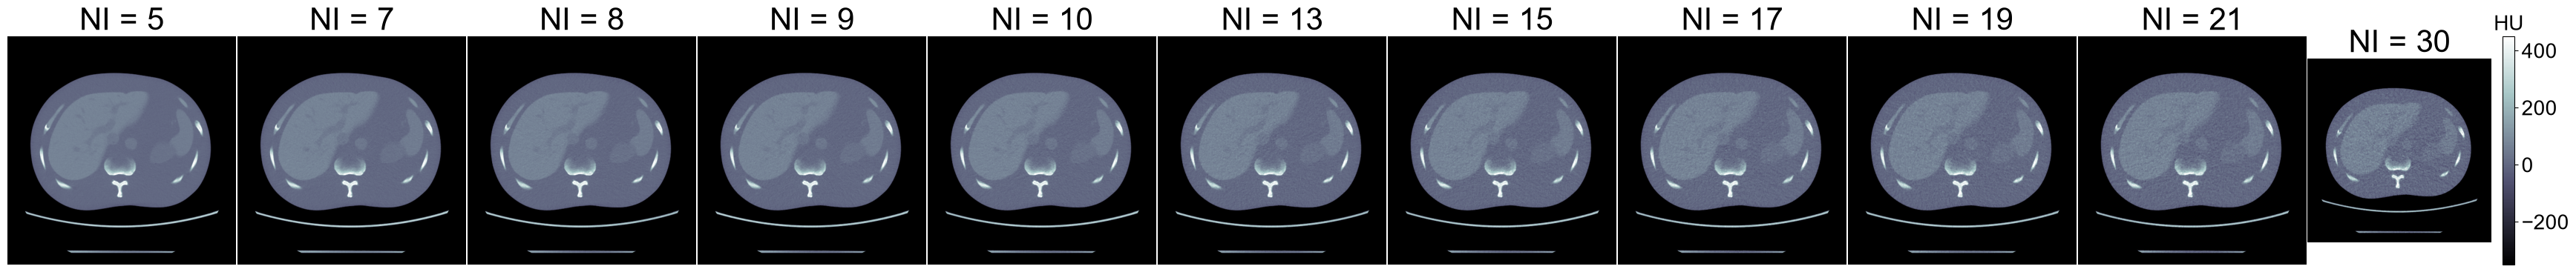

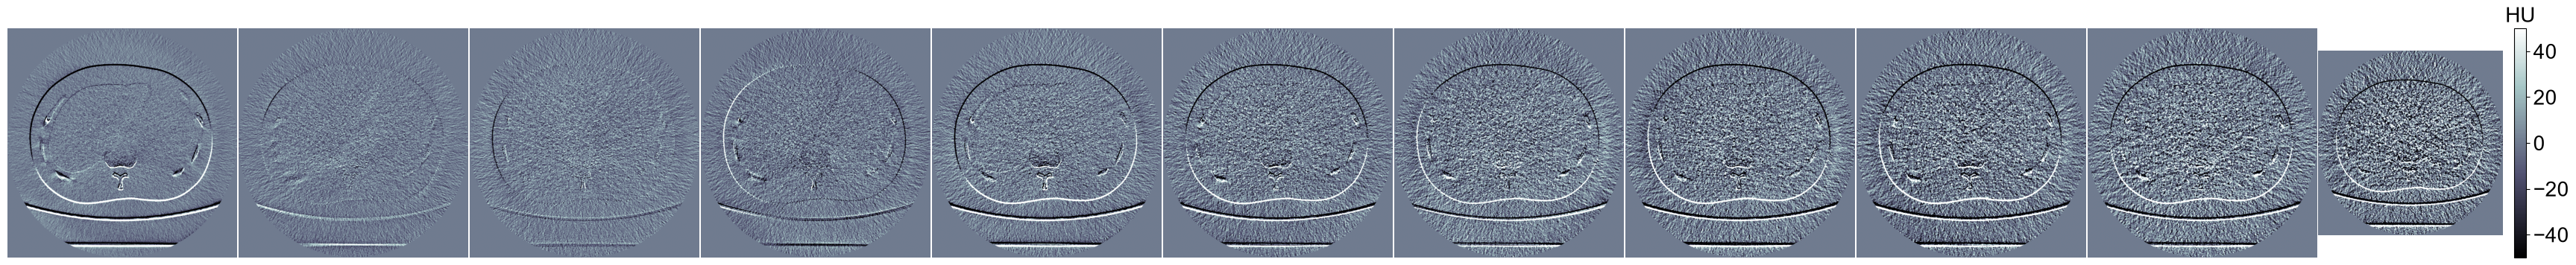

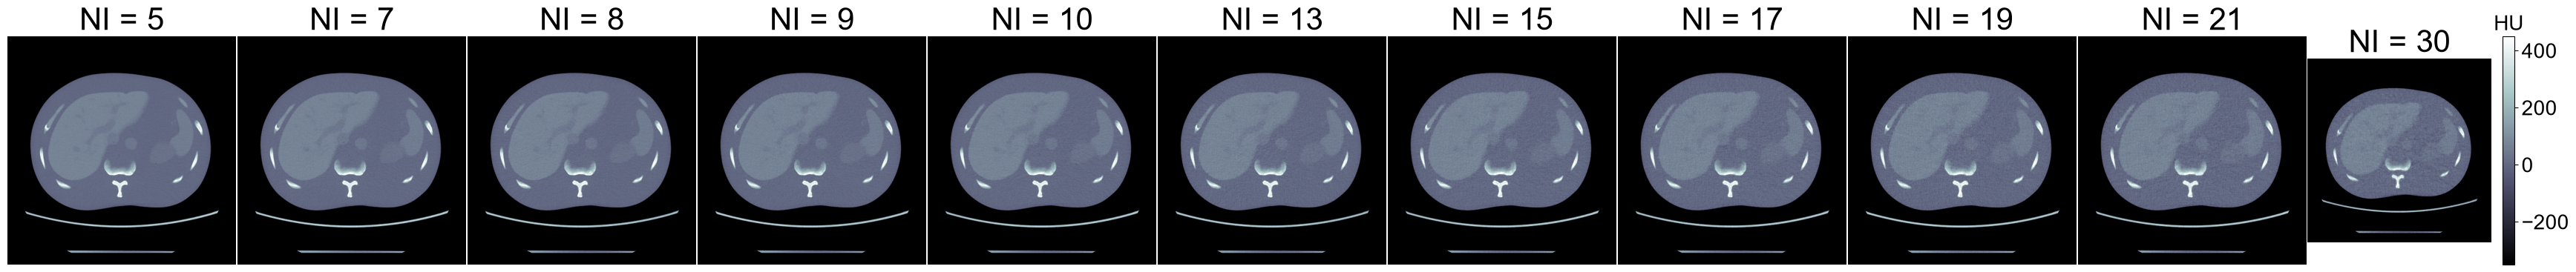

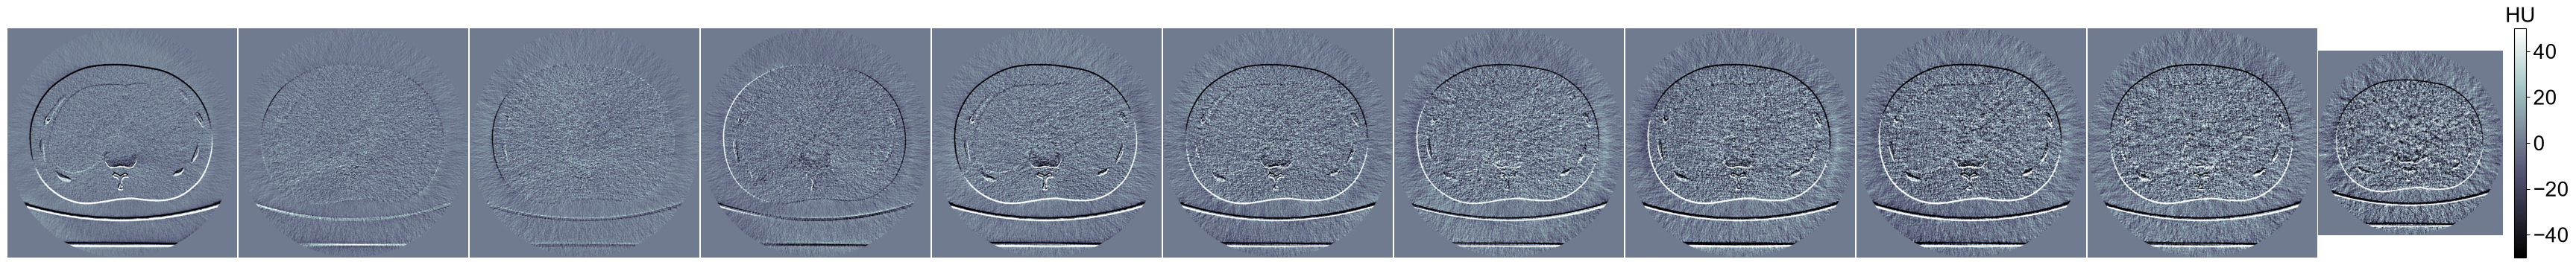

In [5]:
slice_num = 35
all_NI = sorted(all_tube_currents.keys())

for im_type in ['AR50','DLIR']:
    # Acquired Image
    fig,ax = plt.subplots(nrows=1, ncols=len(all_NI), figsize=(len(all_NI)*4,4))
    for n,temp_NI in enumerate(all_NI):
        temp_im = np.squeeze(nib.load(os.path.join(PROJECT_DIR, 'rep1', f'NI-{temp_NI}_{im_type}.nii')).get_fdata())
        temp_im = np.flip(np.transpose(temp_im, (2,1,0)), axis=0)[::-1,:,:]
        ti = ax[n].imshow(temp_im[slice_num-1,:,:], vmin=-350, vmax=450, cmap=plt.cm.bone)
        ax[n].axis('off')
        ax[n].set_title(f'NI = {temp_NI}', fontsize=30)
    plt.subplots_adjust(wspace=0, hspace=0)
    clb = fig.colorbar(ti, ax=ax[n])
    clb.ax.tick_params(labelsize=20) 
    clb.ax.set_title('HU',fontsize=20)
    plt.show()

    # Difference Image
    fig,ax = plt.subplots(nrows=1, ncols=len(all_NI), figsize=(len(all_NI)*4,4))
    for n,temp_NI in enumerate(all_NI):
        all_ims = []
        for rep in [1,2]:
            temp_im = np.squeeze(nib.load(os.path.join(PROJECT_DIR, f'rep{rep}', f'NI-{temp_NI}_{im_type}.nii')).get_fdata())
            temp_im = np.flip(np.transpose(temp_im, (2,1,0)), axis=0)[::-1,:,:]
            all_ims.append(temp_im)
        diff_im = (all_ims[0] - all_ims[1])[slice_num-1,:,:]
        ti = ax[n].imshow(diff_im, vmin=-50, vmax=50, cmap=plt.cm.bone)
        ax[n].axis('off')
    plt.subplots_adjust(wspace=0, hspace=0)
    clb = fig.colorbar(ti, ax=ax[n])
    clb.ax.tick_params(labelsize=20) 
    clb.ax.set_title('HU',fontsize=20)
    plt.show()


# Load the segmentation

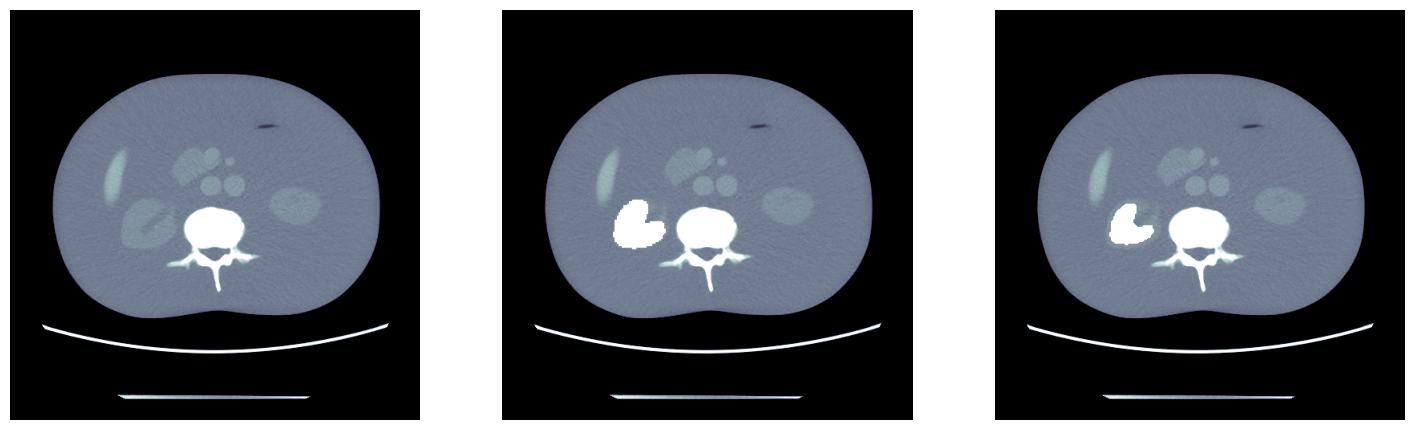

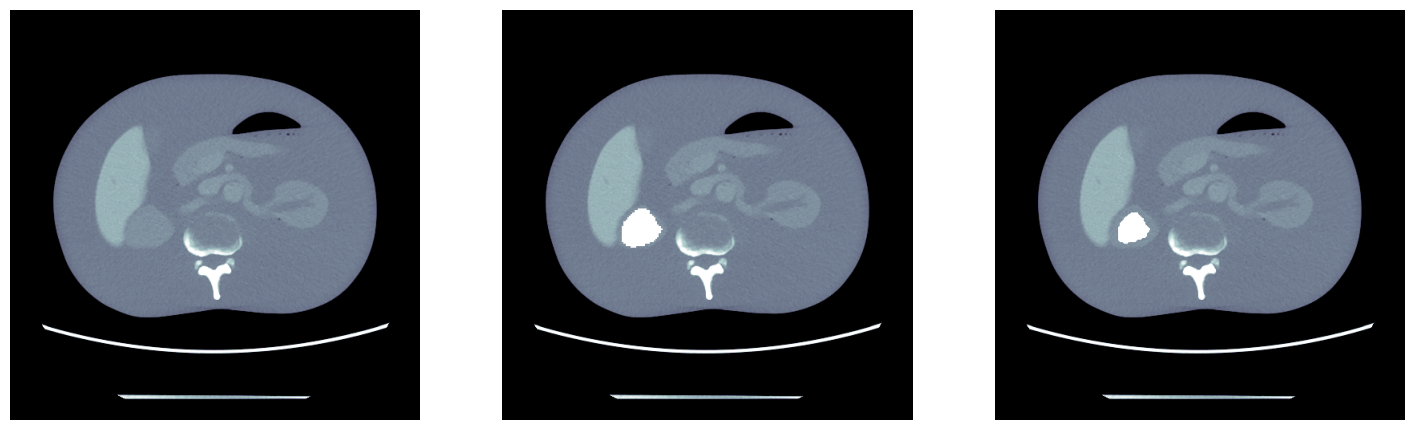

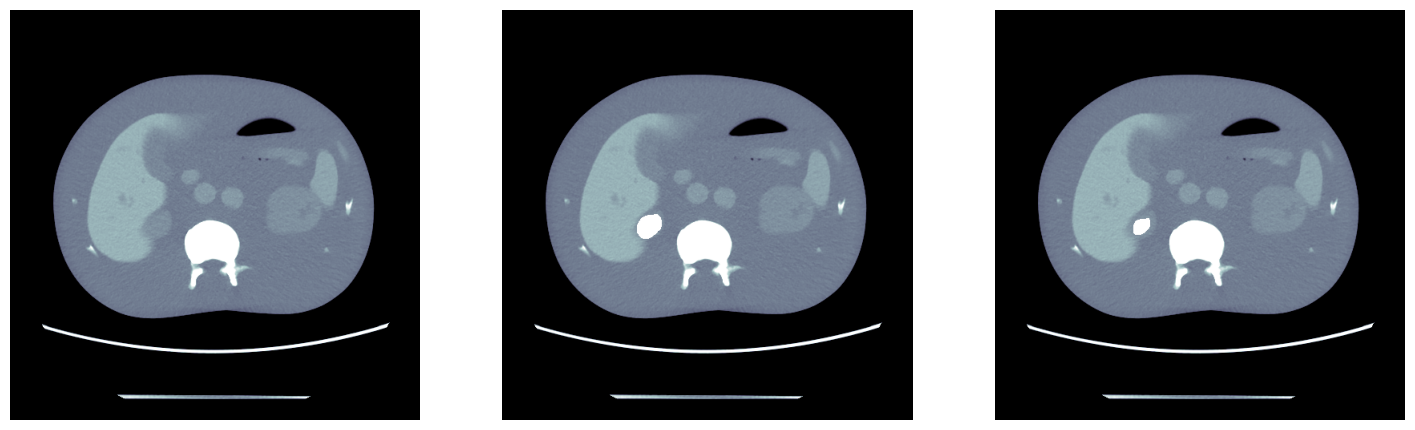

In [6]:
# Load the segmentation
struct_mask = nib.load(os.path.join(PROJECT_DIR, 'segmentation.nii'))
struct_mask = np.transpose(struct_mask.get_fdata(), (2,1,0))
seg_labels = pd.read_csv(os.path.join(PROJECT_DIR, 'segmentation.labels.csv'))
label_dict = seg_labels[['LabelValue','Type_CodeMeaning']].to_dict()
label_dict = label_dict['Type_CodeMeaning']
label_dict = {k:int(v+1) for v,k in label_dict.items()}

# Load the images
all_ims = np.squeeze(nib.load(os.path.join(PROJECT_DIR, 'rep1', 'NI-5_AR50.nii')).get_fdata())
all_ims = np.flip(np.transpose(all_ims, (2,1,0)), axis=0)[::-1,:,:]

# Extract all the values
for temp_slice_location in [20,25,30]:
    temp_im = all_ims[temp_slice_location,:,:].copy()
    temp_seg = struct_mask[temp_slice_location,:,:] == label_dict['Right Kidney']
    temp_im[temp_seg] = np.nan
    temp_seg_eroded = ndimage.binary_erosion(temp_seg, iterations=5).astype(temp_seg.dtype)
    temp_im_eroded = all_ims[temp_slice_location,:,:].copy()
    temp_im_eroded[temp_seg_eroded] = np.nan
    fig,(ax1,ax2,ax3) = plt.subplots(1, 3, figsize=(18,6))
    ax1.imshow(all_ims[temp_slice_location,:,:], vmin=-200, vmax=200, cmap=plt.cm.bone)
    ax2.imshow(temp_im, vmin=-200, vmax=200, cmap=plt.cm.bone)
    ax3.imshow(temp_im_eroded, vmin=-200, vmax=200, cmap=plt.cm.bone)
    ax1.axis('off')
    ax2.axis('off')
    ax3.axis('off')
    plt.show()


# Determine image noise metrics

In [7]:
EROSION = False
all_noise_metrics = {}

for listed_recon_type in ['AR50','DLIR']:
    if listed_recon_type == 'AR50':
        recon_type = 'ASiR-V'
    else:
        recon_type = listed_recon_type
    all_noise_metrics[recon_type] = {}

    # Determine the difference images
    individual_images = {}
    difference_images = {}
    for temp_NI in all_tube_currents.keys():
        # Acquisition 1
        temp_im_1 = np.squeeze(nib.load(os.path.join(PROJECT_DIR, 'rep1', f'NI-{temp_NI}_{listed_recon_type}.nii')).get_fdata())
        temp_im_1 = np.flip(np.transpose(temp_im_1, (2,1,0)), axis=0)[::-1,:,:]

        # Acquisition 2
        temp_im_2 = np.squeeze(nib.load(os.path.join(PROJECT_DIR, 'rep2', f'NI-{temp_NI}_{listed_recon_type}.nii')).get_fdata())
        temp_im_2 = np.flip(np.transpose(temp_im_2, (2,1,0)), axis=0)[::-1,:,:]

        # Difference image
        individual_images[temp_NI] = {
            'im_1': temp_im_1,
            'im_2': temp_im_2
        }
        difference_images[temp_NI] = temp_im_2 - temp_im_1


    # Determine the noise metrics in each struct
    for struct_type in label_dict.keys():
        all_noise_metrics[recon_type][struct_type] = {}
        temp_seg = struct_mask == label_dict[struct_type]
        if EROSION:
            temp_seg = ndimage.binary_erosion(temp_seg, iterations=2).astype(temp_seg.dtype)
        # Difference image method
        # noise_metric = std(im1-im2) / sqrt(2)
        noise_metric = {}
        for temp_NI in difference_images.keys():
            temp_im = difference_images[temp_NI]
            temp_vals = temp_im[temp_seg]
            noise_metric[temp_NI] = np.std(temp_vals) / np.sqrt(2)
        temp_vol =  (np.count_nonzero(temp_seg) * 2.33650378418) / (10**3) # mm^3 --> cm^3
        print(f'{struct_type}: {temp_vol:.0f} cm^3')
        all_noise_metrics[recon_type][struct_type]['noise_metric'] = noise_metric

        # NM-to-NI Ratio (k) = noise_metric / NI
        temp_vals = all_noise_metrics[recon_type][struct_type]['noise_metric']
        all_noise_metrics[recon_type][struct_type]['calibration_factor'] = {
            k: temp_vals[k]/k for k in temp_vals.keys()
        }

        HU_vals = {}
        for temp_NI in individual_images.keys():
            temp_im = individual_images[temp_NI]['im_1']
            temp_vals = list(temp_im[temp_seg])
            temp_im = individual_images[temp_NI]['im_2']
            temp_vals.extend(temp_im[temp_seg])
            HU_vals[temp_NI] = {
                'mean': np.mean(temp_vals),
                'median': np.median(temp_vals)
            }
        all_noise_metrics[recon_type][struct_type]['HU'] = HU_vals

        # ratio expected = NI2 / NI2
        # ratio measured = noise_metric2 / noise_metric1

        # noise ~ 1/sqrt(slice thickness)

all_noise_metrics


Spleen: 141 cm^3
Right Kidney: 88 cm^3
Left Kidney: 88 cm^3
Gallbladder: 15 cm^3
Liver: 1086 cm^3
Stomach: 28 cm^3
Pancreas: 41 cm^3
Left Lung: 376 cm^3
Right Lung: 390 cm^3
L5 Vertebra: 56 cm^3
L4 Vertebra: 55 cm^3
L3 Vertebra: 58 cm^3
L2 Vertebra: 55 cm^3
L1 Vertebra: 48 cm^3
T12 Vertebra: 44 cm^3
T11 Vertebra: 33 cm^3
T10 Vertebra: 20 cm^3
T9 Vertebra: 1 cm^3
Heart: 58 cm^3
Left Hip: 94 cm^3
Right Hip: 90 cm^3
Spinal Cord: 43 cm^3
Left Sixth Rib: 1 cm^3
Left Seventh Rib: 6 cm^3
Left Eighth Rib: 11 cm^3
Left Ninth Rib: 14 cm^3
Left Tenth Rib: 16 cm^3
Left Eleventh Rib: 11 cm^3
Left Twelfth Rib: 6 cm^3
Right Sixth Rib: 4 cm^3
Right Seventh Rib: 4 cm^3
Right Eighth Rib: 7 cm^3
Right Ninth Rib: 16 cm^3
Right Tenth Rib: 17 cm^3
Right Eleventh Rib: 11 cm^3
Right Twelfth Rib: 6 cm^3
Sacrum: 52 cm^3
Spleen: 141 cm^3
Right Kidney: 88 cm^3
Left Kidney: 88 cm^3
Gallbladder: 15 cm^3
Liver: 1086 cm^3
Stomach: 28 cm^3
Pancreas: 41 cm^3
Left Lung: 376 cm^3
Right Lung: 390 cm^3
L5 Vertebra: 56 cm^3

{'ASiR-V': {'Spleen': {'noise_metric': {5: np.float64(5.1739727271143945),
    7: np.float64(7.1138811833697595),
    8: np.float64(8.259529979065556),
    9: np.float64(9.212113205960383),
    10: np.float64(10.009812517437044),
    13: np.float64(12.612175434556578),
    15: np.float64(13.79506765749032),
    17: np.float64(15.009079091671888),
    19: np.float64(16.04337225194772),
    21: np.float64(17.027936345873258),
    30: np.float64(21.97742041687594)},
   'calibration_factor': {5: np.float64(1.0347945454228789),
    7: np.float64(1.0162687404813942),
    8: np.float64(1.0324412473831945),
    9: np.float64(1.0235681339955982),
    10: np.float64(1.0009812517437044),
    13: np.float64(0.9701673411197368),
    15: np.float64(0.9196711771660213),
    17: np.float64(0.882887005392464),
    19: np.float64(0.8443880132604062),
    21: np.float64(0.8108541117082504),
    30: np.float64(0.7325806805625313)},
   'HU': {5: {'mean': np.float64(49.713048146007104),
     'median': np.fl

# Noise metric vs. noise index

Spinal Cord / ASiR-V: a = 2.89 [2.18, 3.82]
Spinal Cord / ASiR-V: b = 0.66 [0.55, 0.77]

Gallbladder / ASiR-V: a = 1.43 [1.15, 1.77]
Gallbladder / ASiR-V: b = 0.82 [0.74, 0.91]

Left Kidney / ASiR-V: a = 1.56 [1.31, 1.86]
Left Kidney / ASiR-V: b = 0.80 [0.73, 0.87]

Right Kidney / ASiR-V: a = 1.64 [1.37, 1.98]
Right Kidney / ASiR-V: b = 0.80 [0.73, 0.87]

Pancreas / ASiR-V: a = 1.52 [1.27, 1.81]
Pancreas / ASiR-V: b = 0.82 [0.75, 0.89]

Spleen / ASiR-V: a = 1.54 [1.33, 1.79]
Spleen / ASiR-V: b = 0.80 [0.74, 0.86]

Liver / ASiR-V: a = 1.71 [1.44, 2.03]
Liver / ASiR-V: b = 0.78 [0.72, 0.85]

Spinal Cord / DLIR: a = 3.60 [2.68, 4.83]
Spinal Cord / DLIR: b = 0.56 [0.45, 0.68]

Gallbladder / DLIR: a = 1.77 [1.43, 2.20]
Gallbladder / DLIR: b = 0.72 [0.64, 0.81]

Left Kidney / DLIR: a = 1.89 [1.60, 2.24]
Left Kidney / DLIR: b = 0.68 [0.62, 0.75]

Right Kidney / DLIR: a = 2.09 [1.69, 2.58]
Right Kidney / DLIR: b = 0.66 [0.58, 0.75]

Pancreas / DLIR: a = 1.85 [1.52, 2.27]
Pancreas / DLIR: b = 0

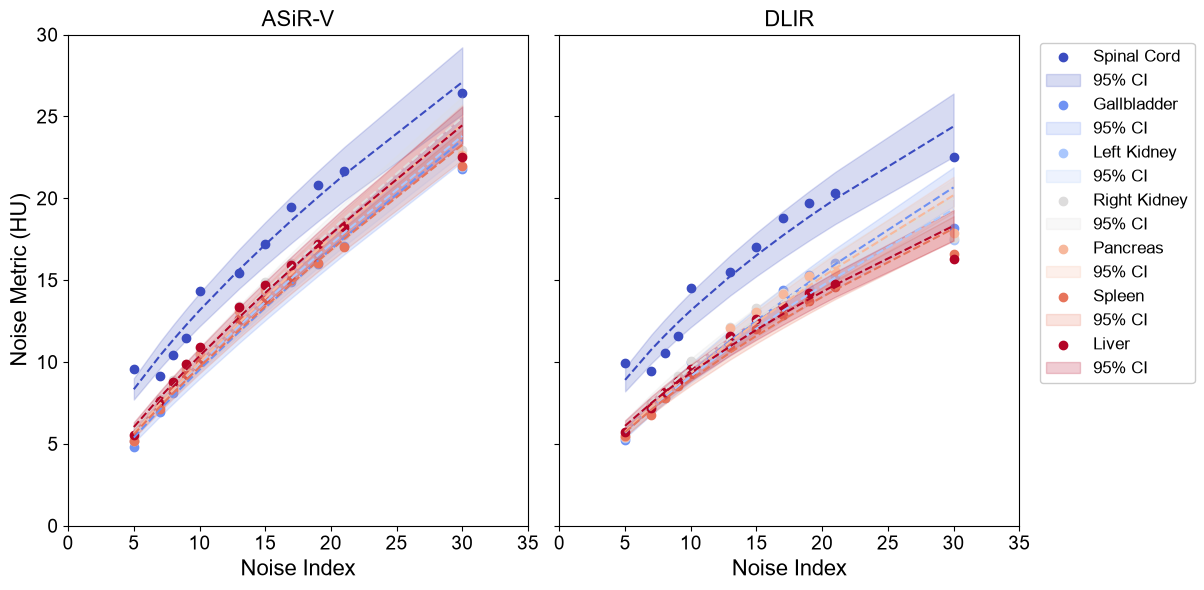

In [8]:
def linear_power_fit(x, y):
    popt_log, pcov_log = curve_fit(lambda x, b, ln_a: b*x + ln_a, np.log(x), np.log(y))
    b_fit, ln_a_fit = popt_log[0], popt_log[1]
    a_fit = np.exp(ln_a_fit)
    return a_fit, b_fit, ln_a_fit, pcov_log

all_fit_params = {}

fig,ax = plt.subplots(nrows=1, ncols=2, sharex=True, sharey=True, figsize=(12,6))

for r,recon_type in enumerate(all_noise_metrics.keys()):
    if recon_type not in all_fit_params.keys():
        all_fit_params[recon_type] = {}
    all_structs = [s for s in all_noise_metrics[recon_type].keys() if (('Vertebra' not in s) and ('Rib' not in s) and ('Lung' not in s) and ('Heart' not in s) and ('Stomach' not in s) and ('Hip' not in s) and ('Sacrum' not in s))]
    # Sort the structs by mean HU
    all_structs = [s[0] for s in sorted([(s,np.mean([all_noise_metrics['ASiR-V'][s]['HU'][ni]['mean'] for ni in all_noise_metrics['ASiR-V'][s]['HU'].keys()])) for s in all_structs], key=lambda s:s[1])]
    plot_colors = plt.colormaps['coolwarm'](np.linspace(0, 1, len(all_structs)))
    for struct_type in all_structs:
        temp_x_data = []
        temp_y_data = []
        for n,temp_NI in enumerate(all_noise_metrics[recon_type][struct_type]['noise_metric'].keys()):
            # Robustness check
            if temp_NI not in []: #[5,7]:
                if n == 0:
                    ax[r].scatter(temp_NI, all_noise_metrics[recon_type][struct_type]['noise_metric'][temp_NI], color=plot_colors[all_structs.index(struct_type)], label=struct_type)
                else:
                    ax[r].scatter(temp_NI, all_noise_metrics[recon_type][struct_type]['noise_metric'][temp_NI], color=plot_colors[all_structs.index(struct_type)])
                temp_x_data.append(temp_NI)
                temp_y_data.append(all_noise_metrics[recon_type][struct_type]['noise_metric'][temp_NI])
        temp_x_data = np.array(temp_x_data).astype(np.float64)
        temp_y_data = np.array(temp_y_data).astype(np.float64)
        # Fitting
        a_fit, b_fit, ln_a_fit, pcov_log = linear_power_fit(temp_x_data, temp_y_data)
        ax[r].plot(temp_x_data, a_fit*(temp_x_data**b_fit), linestyle='--', color=plot_colors[all_structs.index(struct_type)])
        # 95% CI
        n = len(temp_x_data)
        dof = n-2
        t_val = t.ppf(0.975, dof)
        log_y_pred = b_fit * np.log(temp_x_data) + ln_a_fit
        residuals = np.log(temp_y_data) - log_y_pred
        s_err = np.sqrt(np.sum(residuals**2) / dof)
        log_x_mean = np.mean(np.log(temp_x_data))
        s_fit_log = s_err * np.sqrt(1/n + (np.log(temp_x_data) - log_x_mean)**2 / np.sum((np.log(temp_x_data) - log_x_mean)**2))
        log_y_ci_lower = (b_fit * np.log(temp_x_data) + ln_a_fit) - t_val * s_fit_log
        log_y_ci_upper = (b_fit * np.log(temp_x_data) + ln_a_fit) + t_val * s_fit_log
        fit_lower = linear_power_fit(temp_x_data, np.exp(log_y_ci_lower))
        fit_upper = linear_power_fit(temp_x_data, np.exp(log_y_ci_upper))
        ax[r].fill_between(temp_x_data, fit_lower[0]*(temp_x_data**fit_lower[1]), fit_upper[0]*(temp_x_data**fit_upper[1]), color=plot_colors[all_structs.index(struct_type)], alpha=0.2, label='95% CI')
        se_b, se_ln_a = np.sqrt(np.diag(pcov_log))
        b_ci_lower, b_ci_upper = b_fit - t_val * se_b, b_fit + t_val * se_b
        ln_a_ci_lower, ln_a_ci_upper = ln_a_fit - t_val * se_ln_a, ln_a_fit + t_val * se_ln_a
        a_ci_lower, a_ci_upper = np.exp(ln_a_ci_lower), np.exp(ln_a_ci_upper)
        print(f'{struct_type} / {recon_type}: a = {a_fit:.2f} [{a_ci_lower:.2f}, {a_ci_upper:.2f}]')
        print(f'{struct_type} / {recon_type}: b = {b_fit:.2f} [{b_ci_lower:.2f}, {b_ci_upper:.2f}]')
        print()
        all_fit_params[recon_type][struct_type] = {
            # fit, 95% CI min, 95% CI max
            'a': [a_fit, a_ci_lower, a_ci_upper],
            'ln_a': [ln_a_fit, ln_a_ci_lower, ln_a_ci_upper],
            'b': [b_fit, b_ci_lower, b_ci_upper],
            'pcov': pcov_log,
            '95% CI lower': linear_power_fit(temp_x_data, np.exp(log_y_ci_lower)),
            '95% CI upper': linear_power_fit(temp_x_data, np.exp(log_y_ci_upper)),
        }

    ax[r].tick_params(axis='x', labelsize=14)
    ax[r].tick_params(axis='y', labelsize=14)
    ax[r].set_xlim([0,35])
    ax[r].set_ylim([0,30])
    ax[r].set_xlabel('Noise Index', fontsize=16)
    ax[r].set_yticks([0,5,10,15,20,25,30])
    ax[r].set_title(recon_type, fontsize=16)
ax[0].set_ylabel('Noise Metric (HU)', fontsize=16)
plt.legend(bbox_to_anchor=(1.4,1), loc='upper right', framealpha=1, fontsize=12)
plt.tight_layout()
plt.show()


# Test the differences

In [9]:
all_x_data = [all_fit_params['ASiR-V'][d]['b'][0] for d in all_fit_params['ASiR-V']]
all_y_data = [all_fit_params['DLIR'][d]['b'][0] for d in all_fit_params['DLIR']]

stat, p_value = stats.shapiro(all_x_data)
print(f'Stat: {stat:.4f}, p-value: {p_value:.4f}')
stat, p_value = stats.shapiro(all_y_data)
print(f'Stat: {stat:.4f}, p-value: {p_value:.4f}')

print(stats.wilcoxon(all_x_data, all_y_data))
print(np.median(all_x_data), np.median(all_y_data))


Stat: 0.6852, p-value: 0.0026
Stat: 0.9641, p-value: 0.8533
WilcoxonResult(statistic=np.float64(0.0), pvalue=np.float64(0.015625))
0.7997101130561448 0.6638685758151489


# Compare the noise metrics

Spinal Cord: y = 0.90*x + -12.54 (r2 = 0.8928)
Gallbladder: y = 1.06*x + -9.30 (r2 = 0.7179)
Left Kidney: y = 1.12*x + -4.54 (r2 = 0.8704)
Right Kidney: y = 1.24*x + -7.12 (r2 = 0.8888)
Pancreas: y = 1.08*x + -5.38 (r2 = 0.7992)
Spleen: y = 1.45*x + -7.50 (r2 = 0.9037)
Liver: y = 1.51*x + -7.24 (r2 = 0.9279)


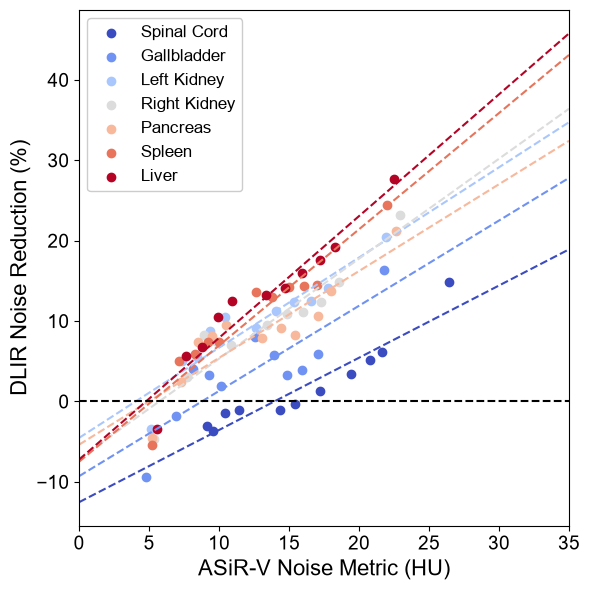

Spinal Cord / DLIR: a = 1.43 [1.22, 1.67]
Spinal Cord / DLIR: b = 0.86 [0.80, 0.92]

Gallbladder / DLIR: a = 1.30 [1.13, 1.50]
Gallbladder / DLIR: b = 0.87 [0.82, 0.93]

Left Kidney / DLIR: a = 1.29 [1.19, 1.41]
Left Kidney / DLIR: b = 0.85 [0.82, 0.89]

Right Kidney / DLIR: a = 1.37 [1.22, 1.55]
Right Kidney / DLIR: b = 0.83 [0.79, 0.88]

Pancreas / DLIR: a = 1.29 [1.13, 1.48]
Pancreas / DLIR: b = 0.86 [0.81, 0.91]

Spleen / DLIR: a = 1.42 [1.29, 1.56]
Spleen / DLIR: b = 0.81 [0.77, 0.85]

Liver / DLIR: a = 1.48 [1.32, 1.65]
Liver / DLIR: b = 0.79 [0.74, 0.83]



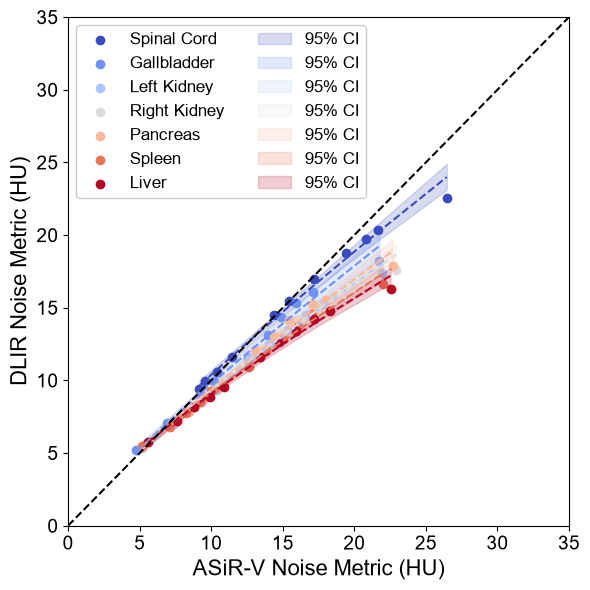

In [10]:
def linear_power_fit(x, y):
    popt_log, pcov_log = curve_fit(lambda x, b, ln_a: b * x + ln_a, np.log(x), np.log(y))
    b_fit, ln_a_fit = popt_log[0], popt_log[1]
    a_fit = np.exp(ln_a_fit)
    return a_fit, b_fit, ln_a_fit, pcov_log

def linear_slope(x, a, b):
    return a*x + b

def power_slope(x, a, b):
    return a*(x**b)


for PERCENT in [True,False]:
    plt.figure(figsize=(6,6))
    ax = plt.gca()
    ax.tick_params(axis='x', labelsize=14)
    ax.tick_params(axis='y', labelsize=14)

    all_structs = [s for s in all_noise_metrics[recon_type].keys() if (('Vertebra' not in s) and ('Rib' not in s) and ('Lung' not in s) and ('Heart' not in s) and ('Stomach' not in s) and ('Hip' not in s) and ('Sacrum' not in s))]
    # Sort the structs by mean HU
    all_structs = [s[0] for s in sorted([(s,np.mean([all_noise_metrics['ASiR-V'][s]['HU'][ni]['mean'] for ni in all_noise_metrics['ASiR-V'][s]['HU'].keys()])) for s in all_structs], key=lambda s:s[1])]
    plot_colors = plt.colormaps['coolwarm'](np.linspace(0, 1, len(all_structs)))

    if not PERCENT:
        all_NM_fits = {}
    for struct_type in all_structs:
        all_x_data = []
        all_y_data = []
        for n,temp_NI in enumerate(all_noise_metrics[recon_type][struct_type]['noise_metric'].keys()):
            temp_x_data = all_noise_metrics['ASiR-V'][struct_type]['noise_metric'][temp_NI]
            temp_y_data = all_noise_metrics['DLIR'][struct_type]['noise_metric'][temp_NI]
            if PERCENT:
                temp_y_data = 100 * (temp_x_data - temp_y_data) / temp_x_data
            if n == 0:
                plt.scatter(temp_x_data, temp_y_data, color=plot_colors[all_structs.index(struct_type)], label=struct_type)
            else:
                plt.scatter(temp_x_data, temp_y_data, color=plot_colors[all_structs.index(struct_type)])
            all_x_data.append(temp_x_data)
            all_y_data.append(temp_y_data)

        all_x_data = np.array(all_x_data).astype(np.float64)
        all_y_data = np.array(all_y_data).astype(np.float64)
        if PERCENT:
            popt, pcov = curve_fit(linear_slope, all_x_data, all_y_data, p0=[1,0])
            y_pred = linear_slope(all_x_data, *popt)
        else:
            popt, pcov = curve_fit(power_slope, all_x_data, all_y_data, p0=[1,1])
            y_pred = power_slope(all_x_data, *popt)
        ss_res = np.sum((all_y_data - y_pred) ** 2)
        ss_tot = np.sum((all_y_data - np.mean(all_y_data)) ** 2)
        r_squared = 1 - (ss_res / ss_tot)
        plot_x_data = np.arange(0,36,1)
        if PERCENT:
            print(f'{struct_type}: y = {popt[0]:.2f}*x + {popt[1]:.2f} (r2 = {r_squared:.4f})')
            plt.plot(plot_x_data, linear_slope(plot_x_data, *popt), linestyle='--', color=plot_colors[all_structs.index(struct_type)])
        else:
            # Fitting
            a_fit, b_fit, ln_a_fit, pcov_log = linear_power_fit(all_x_data, all_y_data)
            plt.plot(all_x_data, a_fit*(all_x_data**b_fit), linestyle='--', color=plot_colors[all_structs.index(struct_type)])
            # 95% CI
            n = len(all_x_data)
            dof = n-2
            t_val = t.ppf(0.975, dof)
            log_y_pred = b_fit * np.log(all_x_data) + ln_a_fit
            residuals = np.log(all_y_data) - log_y_pred
            s_err = np.sqrt(np.sum(residuals**2) / dof)
            log_x_mean = np.mean(np.log(all_x_data))
            s_fit_log = s_err * np.sqrt(1/n + (np.log(all_x_data) - log_x_mean)**2 / np.sum((np.log(all_x_data) - log_x_mean)**2))
            log_y_ci_lower = (b_fit*np.log(all_x_data) + ln_a_fit) - t_val*s_fit_log
            log_y_ci_upper = (b_fit*np.log(all_x_data) + ln_a_fit) + t_val*s_fit_log
            plt.fill_between(all_x_data, np.exp(log_y_ci_lower), np.exp(log_y_ci_upper), color=plot_colors[all_structs.index(struct_type)], alpha=0.2, label='95% CI')
            se_b, se_ln_a = np.sqrt(np.diag(pcov_log))
            b_ci_lower, b_ci_upper = b_fit - t_val*se_b, b_fit + t_val*se_b
            ln_a_ci_lower, ln_a_ci_upper = ln_a_fit - t_val*se_ln_a, ln_a_fit + t_val*se_ln_a
            a_ci_lower, a_ci_upper = np.exp(ln_a_ci_lower), np.exp(ln_a_ci_upper)
            print(f'{struct_type} / {recon_type}: a = {a_fit:.2f} [{a_ci_lower:.2f}, {a_ci_upper:.2f}]')
            print(f'{struct_type} / {recon_type}: b = {b_fit:.2f} [{b_ci_lower:.2f}, {b_ci_upper:.2f}]')
            print()
            all_NM_fits[struct_type] = {
                'a': a_fit,
                'b': b_fit,
                'a_log': ln_a_fit,
                'pcov_log': pcov_log
            }

    plt.tick_params(axis='x', labelsize=14)
    plt.tick_params(axis='y', labelsize=14)
    if PERCENT:
        plt.plot([0,35], [0,0], linestyle='--', color='k')
    else:
        plt.plot([0,35], [0,35], linestyle='--', color='k')
    plt.xlim([0,35])
    if PERCENT:
        plt.ylabel('DLIR Noise Reduction (%)', fontsize=16)
        plt.legend(loc='upper left', framealpha=1, fontsize=12)
    else:
        plt.ylim([0,35])
        plt.ylabel('DLIR Noise Metric (HU)', fontsize=16)
        def reorder_legend_left_to_right(handles, labels, ncol):
            reordered_handles = sum([handles[i::ncol] for _,i in enumerate(range(ncol))], [])
            reordered_labels = sum([labels[i::ncol] for _,i in enumerate(range(ncol))], [])
            return reordered_handles, reordered_labels
        ax = plt.gca()
        handles,labels = ax.get_legend_handles_labels()
        h,l = reorder_legend_left_to_right(handles, labels, ncol=2)
        ax.legend(h, l, loc='upper left', ncols=2, framealpha=1, fontsize=12)
    plt.xlabel('ASiR-V Noise Metric (HU)', fontsize=16)
    plt.tight_layout()
    plt.show()


# Find CTDIvol at equivalent NI

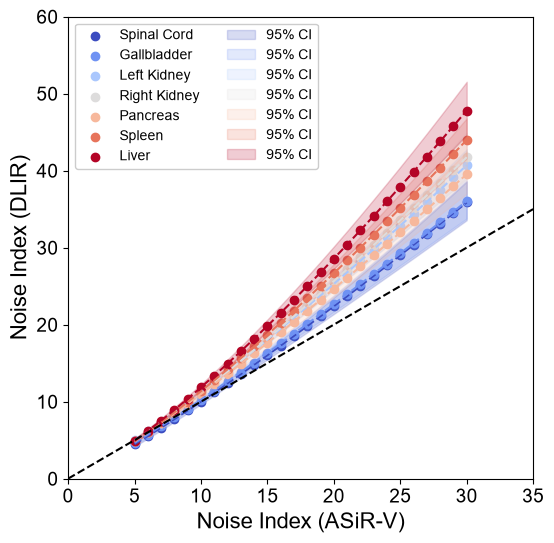

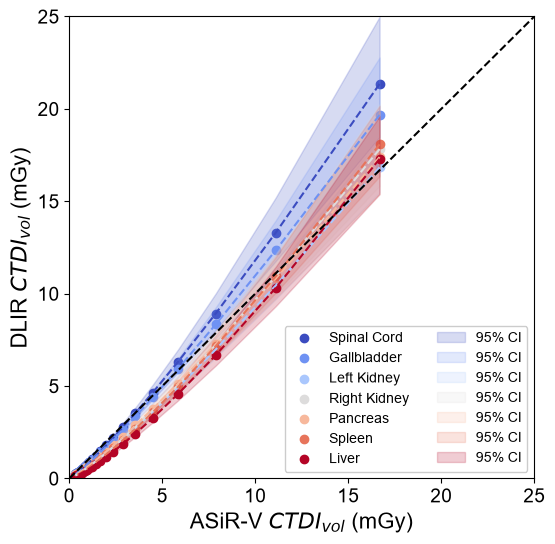

NI / Spinal Cord = 15.01 [11.56, 18.33]
Dose Reduction / Spinal Cord = 0.20 [0.11, 0.33]


C:\Users\CH279347\AppData\Local\Temp\ipykernel_26456\2760540994.py:116: RuntimeWarning: The iteration is not making good progress, as measured by the 
 improvement from the last ten iterations.
  root = fsolve(temp_derivative, x0=5, maxfev=1000)[0]


NI / Gallbladder = 12.68 [8.95, 15.69]
Dose Reduction / Gallbladder = 0.27 [0.16, 0.44]


C:\Users\CH279347\AppData\Local\Temp\ipykernel_26456\2760540994.py:115: RuntimeWarning: invalid value encountered in power
  temp_derivative = lambda x: (CTDIVOL_FIT[0] * CTDIVOL_FIT[1] * (x**(CTDIVOL_FIT[1] - 1))) - (CTDIVOL_FIT[0] * (((aA_sim[i]**(1-bNM_sim[i]))/aNM_sim[i])**(CTDIVOL_FIT[1]/(bA_sim[i]*bNM_sim[i]))) * (CTDIVOL_FIT[1]/bNM_sim[i]) * ((x)**((CTDIVOL_FIT[1]/bNM_sim[i])-1)))


NI / Left Kidney = 7.74 [5.92, 9.29]
Dose Reduction / Left Kidney = 0.93 [0.69, 1.40]
NI / Right Kidney = 8.69 [6.50, 10.55]
Dose Reduction / Right Kidney = 0.82 [0.59, 1.26]
NI / Pancreas = 8.45 [5.59, 10.80]
Dose Reduction / Pancreas = 0.74 [0.49, 1.33]
NI / Spleen = 8.71 [7.14, 10.08]
Dose Reduction / Spleen = 0.92 [0.72, 1.23]
NI / Liver = 7.88 [6.33, 9.26]
Dose Reduction / Liver = 1.29 [0.98, 1.81]


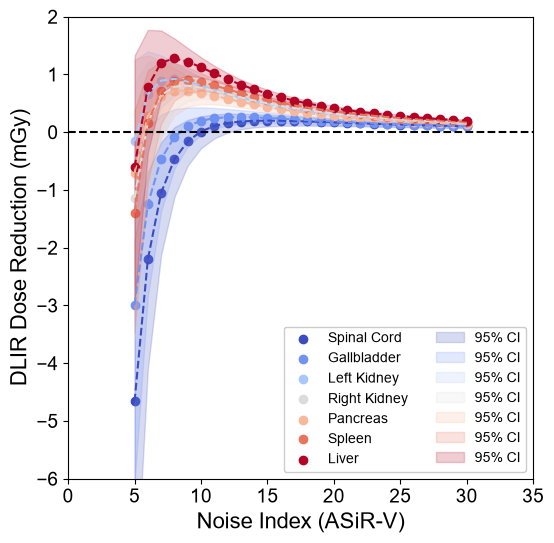

In [11]:
all_structs = [s for s in all_noise_metrics[recon_type].keys() if (('Vertebra' not in s) and ('Rib' not in s) and ('Lung' not in s) and ('Heart' not in s) and ('Stomach' not in s) and ('Hip' not in s) and ('Sacrum' not in s))]
# Sort the structs by mean HU
all_structs = [s[0] for s in sorted([(s,np.mean([all_noise_metrics['ASiR-V'][s]['HU'][ni]['mean'] for ni in all_noise_metrics['ASiR-V'][s]['HU'].keys()])) for s in all_structs], key=lambda s:s[1])]
plot_colors = plt.colormaps['coolwarm'](np.linspace(0, 1, len(all_structs)))


n_sims = 10000
plt.figure(figsize=(6,6))
for s,struct_type in enumerate(all_structs):
    asir_b_mean = all_fit_params['ASiR-V'][struct_type]['b'][0]
    asir_ln_a_mean = all_fit_params['ASiR-V'][struct_type]['ln_a'][0]
    asir_pcov = all_fit_params['ASiR-V'][struct_type]['pcov']
    asir_sims = np.random.multivariate_normal([asir_b_mean, asir_ln_a_mean], asir_pcov, n_sims)
    bA_sim = asir_sims[:,0]
    aA_sim = np.exp(asir_sims[:,1])
    bNM_mean = all_NM_fits[struct_type]['b']
    a_log_NM_mean = all_NM_fits[struct_type]['a_log']
    nm_pcov = all_NM_fits[struct_type]['pcov_log']
    nm_sims = np.random.multivariate_normal([bNM_mean, a_log_NM_mean], nm_pcov, n_sims)
    bNM_sim = nm_sims[:,0]
    aNM_sim = np.exp(nm_sims[:,1])
    NI_range = np.arange(5,31,1)
    sim_y_matrix = np.zeros((n_sims, len(NI_range)))
    for i in range(n_sims):
        sim_y_matrix[i,:] = ((aA_sim[i] ** (1 - bNM_sim[i])) / aNM_sim[i]) ** (1 / (bA_sim[i] * bNM_sim[i])) * (NI_range ** (1 / bNM_sim[i]))
    aA_nominal = np.exp(asir_ln_a_mean)
    aNM_nominal = np.exp(a_log_NM_mean)
    nom_y = ((aA_nominal ** (1 - bNM_mean)) / aNM_nominal) ** (1 / (asir_b_mean * bNM_mean)) * (NI_range ** (1 / bNM_mean))
    ci_lower = np.percentile(sim_y_matrix, 2.5, axis=0)
    ci_upper = np.percentile(sim_y_matrix, 97.5, axis=0)
    plt.scatter(NI_range, nom_y, color=plot_colors[s], label=struct_type)
    plt.plot(NI_range, nom_y, linestyle='--', color=plot_colors[s])
    plt.fill_between(NI_range, ci_lower, ci_upper, color=plot_colors[s], alpha=0.2, label='95% CI')
plt.plot([0,35], [0,35], linestyle='--', color='k')
plt.tick_params(axis='x', labelsize=14)
plt.tick_params(axis='y', labelsize=14)
plt.xlim([0,35])
plt.ylim([0,60])
plt.xlabel('Noise Index (ASiR-V)', fontsize=16)
plt.ylabel('Noise Index (DLIR)', fontsize=16)
ax = plt.gca()
handles,labels = ax.get_legend_handles_labels()
reordered_handles = sum([handles[i::2] for _,i in enumerate(range(2))], [])
reordered_labels = sum([labels[i::2] for _,i in enumerate(range(2))], [])
ax.legend(reordered_handles, reordered_labels, loc='upper left', ncols=2, framealpha=1, fontsize=10)
plt.show()


plt.figure(figsize=(6,6))
for s,struct_type in enumerate(all_structs):
    asir_b_mean = all_fit_params['ASiR-V'][struct_type]['b'][0]
    asir_ln_a_mean = all_fit_params['ASiR-V'][struct_type]['ln_a'][0]
    asir_pcov = all_fit_params['ASiR-V'][struct_type]['pcov']
    asir_sims = np.random.multivariate_normal([asir_b_mean, asir_ln_a_mean], asir_pcov, n_sims)
    bA_sim = asir_sims[:,0]
    aA_sim = np.exp(asir_sims[:,1])
    bNM_mean = all_NM_fits[struct_type]['b']
    a_log_NM_mean = all_NM_fits[struct_type]['a_log']
    nm_pcov = all_NM_fits[struct_type]['pcov_log']
    nm_sims = np.random.multivariate_normal([bNM_mean, a_log_NM_mean], nm_pcov, n_sims)
    bNM_sim = nm_sims[:,0]
    aNM_sim = np.exp(nm_sims[:,1])
    NI_range = np.arange(5,31,1)
    sim_y_matrix = np.zeros((n_sims, len(NI_range)))
    for i in range(n_sims):
        temp_CTDIvol_D = CTDIVOL_FIT[0] * (((aA_sim[i]**(1-bNM_sim[i]))/aNM_sim[i])**(CTDIVOL_FIT[1]/(bA_sim[i]*bNM_sim[i]))) * ((NI_range)**(CTDIVOL_FIT[1]/bNM_sim[i]))
        sim_y_matrix[i,:] = temp_CTDIvol_D
    aA_nominal = np.exp(asir_ln_a_mean)
    aNM_nominal = np.exp(a_log_NM_mean)
    temp_CTDIvol_A = CTDIVOL_FIT[0] * (NI_range**CTDIVOL_FIT[1])
    temp_CTDIvol_D = CTDIVOL_FIT[0] * (((aA_nominal**(1-bNM_mean))/aNM_nominal)**(CTDIVOL_FIT[1]/(asir_b_mean*bNM_mean))) * ((NI_range)**(CTDIVOL_FIT[1]/bNM_mean))
    nom_y = temp_CTDIvol_D
    ci_lower = np.percentile(sim_y_matrix, 2.5, axis=0)
    ci_upper = np.percentile(sim_y_matrix, 97.5, axis=0)
    plt.scatter(temp_CTDIvol_A, nom_y, color=plot_colors[s], label=struct_type)
    plt.plot(temp_CTDIvol_A, nom_y, linestyle='--', color=plot_colors[s])
    plt.fill_between(temp_CTDIvol_A, ci_lower, ci_upper, color=plot_colors[s], alpha=0.2, label='95% CI')
plt.plot([0,35], [0,35], linestyle='--', color='k')
plt.tick_params(axis='x', labelsize=14)
plt.tick_params(axis='y', labelsize=14)
plt.xlim([0,25])
plt.ylim([0,25])
plt.xlabel('ASiR-V $CTDI_{vol}$ (mGy)', fontsize=16)
plt.ylabel('DLIR $CTDI_{vol}$ (mGy)', fontsize=16)
ax = plt.gca()
handles,labels = ax.get_legend_handles_labels()
reordered_handles = sum([handles[i::2] for _,i in enumerate(range(2))], [])
reordered_labels = sum([labels[i::2] for _,i in enumerate(range(2))], [])
ax.legend(reordered_handles, reordered_labels, loc='lower right', ncols=2, framealpha=1, fontsize=10)
plt.show()


plt.figure(figsize=(6,6))
for s,struct_type in enumerate(all_structs):
    asir_b_mean = all_fit_params['ASiR-V'][struct_type]['b'][0]
    asir_ln_a_mean = all_fit_params['ASiR-V'][struct_type]['ln_a'][0]
    asir_pcov = all_fit_params['ASiR-V'][struct_type]['pcov']
    asir_sims = np.random.multivariate_normal([asir_b_mean, asir_ln_a_mean], asir_pcov, n_sims)
    bA_sim = asir_sims[:,0]
    aA_sim = np.exp(asir_sims[:,1])
    bNM_mean = all_NM_fits[struct_type]['b']
    a_log_NM_mean = all_NM_fits[struct_type]['a_log']
    nm_pcov = all_NM_fits[struct_type]['pcov_log']
    nm_sims = np.random.multivariate_normal([bNM_mean, a_log_NM_mean], nm_pcov, n_sims)
    bNM_sim = nm_sims[:,0]
    aNM_sim = np.exp(nm_sims[:,1])
    NI_range = np.arange(5,31,1)
    sim_y_matrix = np.zeros((n_sims, len(NI_range)))
    all_roots = []
    all_dr = []
    for i in range(n_sims):
        temp_CTDIvol_A = CTDIVOL_FIT[0] * (NI_range**CTDIVOL_FIT[1])
        temp_CTDIvol_D = CTDIVOL_FIT[0] * (((aA_sim[i]**(1-bNM_sim[i]))/aNM_sim[i])**(CTDIVOL_FIT[1]/(bA_sim[i]*bNM_sim[i]))) * ((NI_range)**(CTDIVOL_FIT[1]/bNM_sim[i]))
        sim_y_matrix[i,:] = temp_CTDIvol_A - temp_CTDIvol_D
        temp_derivative = lambda x: (CTDIVOL_FIT[0] * CTDIVOL_FIT[1] * (x**(CTDIVOL_FIT[1] - 1))) - (CTDIVOL_FIT[0] * (((aA_sim[i]**(1-bNM_sim[i]))/aNM_sim[i])**(CTDIVOL_FIT[1]/(bA_sim[i]*bNM_sim[i]))) * (CTDIVOL_FIT[1]/bNM_sim[i]) * ((x)**((CTDIVOL_FIT[1]/bNM_sim[i])-1)))
        root = fsolve(temp_derivative, x0=5, maxfev=1000)[0]
        all_roots.append(root)
        all_dr.append(
            (CTDIVOL_FIT[0] * (root**CTDIVOL_FIT[1])) - (CTDIVOL_FIT[0] * (((aA_sim[i]**(1-bNM_sim[i]))/aNM_sim[i])**(CTDIVOL_FIT[1]/(bA_sim[i]*bNM_sim[i]))) * ((root)**(CTDIVOL_FIT[1]/bNM_sim[i])))
        )
    aA_nominal = np.exp(asir_ln_a_mean)
    aNM_nominal = np.exp(a_log_NM_mean)
    temp_CTDIvol_A = CTDIVOL_FIT[0] * (NI_range**CTDIVOL_FIT[1])
    temp_CTDIvol_D = CTDIVOL_FIT[0] * (((aA_nominal**(1-bNM_mean))/aNM_nominal)**(CTDIVOL_FIT[1]/(asir_b_mean*bNM_mean))) * ((NI_range)**(CTDIVOL_FIT[1]/bNM_mean))
    nom_y = temp_CTDIvol_A - temp_CTDIvol_D
    ci_lower = np.percentile(sim_y_matrix, 2.5, axis=0)
    ci_upper = np.percentile(sim_y_matrix, 97.5, axis=0)
    plt.scatter(NI_range, nom_y, color=plot_colors[s], label=struct_type)
    plt.plot(NI_range, nom_y, linestyle='--', color=plot_colors[s])
    plt.fill_between(NI_range, ci_lower, ci_upper, color=plot_colors[s], alpha=0.2, label='95% CI')
    # Same as previously derived
    # print(f'{struct_type}: aA = {np.percentile(aA_sim, 50, axis=0):.2f} [{np.percentile(aA_sim, 2.5, axis=0):.2f}, {np.percentile(aA_sim, 97.5, axis=0):.2f}]')
    # print(f'{struct_type}: bA = {np.percentile(bA_sim, 50, axis=0):.2f} [{np.percentile(bA_sim, 2.5, axis=0):.2f}, {np.percentile(bA_sim, 97.5, axis=0):.2f}]')
    # print(f'{struct_type}: bNM = {np.percentile(bNM_sim, 50, axis=0):.2f} [{np.percentile(bNM_sim, 2.5, axis=0):.2f}, {np.percentile(bNM_sim, 97.5, axis=0):.2f}]')
    all_roots = np.array(all_roots)
    all_dr = np.array(all_dr)
    all_roots = all_roots[~np.isnan(all_roots)]
    all_dr = all_dr[~np.isnan(all_dr)]
    print(f'NI / {struct_type} = {np.percentile(all_roots,50):.2f} [{np.percentile(all_roots,2.5):.2f}, {np.percentile(all_roots,97.5):.2f}]')
    print(f'Dose Reduction / {struct_type} = {np.percentile(all_dr,50):.2f} [{np.percentile(all_dr,2.5):.2f}, {np.percentile(all_dr,97.5):.2f}]')
plt.plot([0,35], [0,0], linestyle='--', color='k')
plt.tick_params(axis='x', labelsize=14)
plt.tick_params(axis='y', labelsize=14)
plt.xlim([0,35])
plt.ylim([-6,2])
plt.xlabel('Noise Index (ASiR-V)', fontsize=16)
plt.ylabel('DLIR Dose Reduction (mGy)', fontsize=16)
ax = plt.gca()
handles,labels = ax.get_legend_handles_labels()
reordered_handles = sum([handles[i::2] for _,i in enumerate(range(2))], [])
reordered_labels = sum([labels[i::2] for _,i in enumerate(range(2))], [])
ax.legend(reordered_handles, reordered_labels, loc='lower right', ncols=2, framealpha=1, fontsize=10)
plt.show()


# Noise metric vs. HU

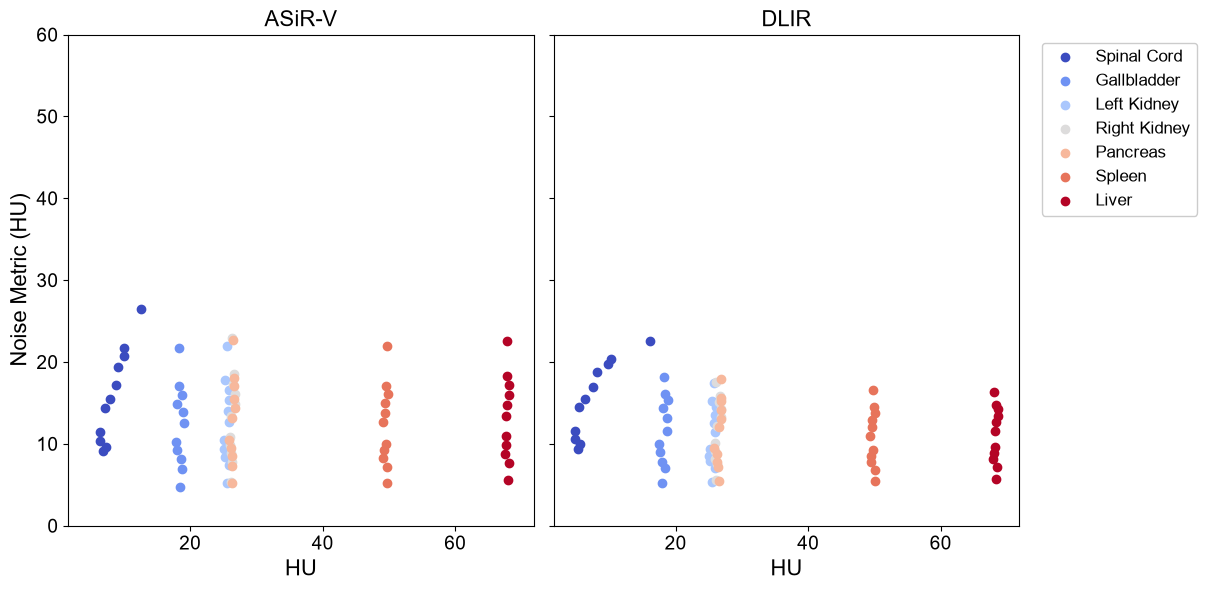

ASiR-V, Spinal Cord: 8
ASiR-V, Gallbladder: 18
ASiR-V, Left Kidney: 26
ASiR-V, Right Kidney: 26
ASiR-V, Pancreas: 26
ASiR-V, Spleen: 49
ASiR-V, Liver: 68
DLIR, Spinal Cord: 8
DLIR, Gallbladder: 18
DLIR, Left Kidney: 26
DLIR, Right Kidney: 26
DLIR, Pancreas: 27
DLIR, Spleen: 50
DLIR, Liver: 68


In [12]:
fig,ax = plt.subplots(nrows=1, ncols=2, sharex=True, sharey=True, figsize=(12,6))

all_HU = {}
for r,recon_type in enumerate(all_noise_metrics.keys()):
    all_HU[recon_type] = {}
    all_structs = [s for s in all_noise_metrics[recon_type].keys() if (('Vertebra' not in s) and ('Rib' not in s) and ('Lung' not in s) and ('Heart' not in s) and ('Stomach' not in s) and ('Hip' not in s) and ('Sacrum' not in s))]
    # Sort the structs by mean HU
    all_structs = [s[0] for s in sorted([(s,np.mean([all_noise_metrics['ASiR-V'][s]['HU'][ni]['mean'] for ni in all_noise_metrics['ASiR-V'][s]['HU'].keys()])) for s in all_structs], key=lambda s:s[1])]
    plot_colors = plt.colormaps['coolwarm'](np.linspace(0, 1, len(all_structs)))
    for struct_type in all_structs:
        all_HU[recon_type][struct_type] = []
        for n,temp_NI in enumerate(all_noise_metrics[recon_type][struct_type]['noise_metric'].keys()):
            if n == 0:
                ax[r].scatter(
                    all_noise_metrics[recon_type][struct_type]['HU'][temp_NI]['mean'],
                    all_noise_metrics[recon_type][struct_type]['noise_metric'][temp_NI],
                    color=plot_colors[all_structs.index(struct_type)], label=struct_type
                )
            else:
                ax[r].scatter(
                    all_noise_metrics[recon_type][struct_type]['HU'][temp_NI]['mean'],
                    all_noise_metrics[recon_type][struct_type]['noise_metric'][temp_NI],
                    color=plot_colors[all_structs.index(struct_type)]
                )
            all_HU[recon_type][struct_type].append(all_noise_metrics[recon_type][struct_type]['HU'][temp_NI]['mean'])
    ax[r].tick_params(axis='x', labelsize=14)
    ax[r].tick_params(axis='y', labelsize=14)
    ax[r].set_ylim([0,60])
    ax[r].set_xlabel('HU', fontsize=16)
    ax[r].set_title(recon_type, fontsize=16)
ax[0].set_ylabel('Noise Metric (HU)', fontsize=16)
plt.legend(bbox_to_anchor=(1.4,1), loc='upper right', framealpha=1, fontsize=12)
plt.tight_layout()
plt.show()


for recon_type in all_noise_metrics.keys():
    for struct_type in all_structs:
        print(f'{recon_type}, {struct_type}: {np.mean(all_HU[recon_type][struct_type]):.0f}')


# NM-to-NI Ratio vs. noise index (derived)

Spinal Cord / ASiR-V: y = 2.89x^-0.34 (r2 = 0.85)
Parameter a: 2.89 (95% CI: 2.18 to 3.82)
Parameter b: 0.66 (95% CI: 0.55 to 0.77)

Gallbladder / ASiR-V: y = 1.43x^-0.18 (r2 = 0.71)
Parameter a: 1.43 (95% CI: 1.15 to 1.77)
Parameter b: 0.82 (95% CI: 0.74 to 0.91)

Left Kidney / ASiR-V: y = 1.56x^-0.20 (r2 = 0.83)
Parameter a: 1.56 (95% CI: 1.31 to 1.86)
Parameter b: 0.80 (95% CI: 0.73 to 0.87)

Right Kidney / ASiR-V: y = 1.64x^-0.20 (r2 = 0.81)
Parameter a: 1.64 (95% CI: 1.37 to 1.98)
Parameter b: 0.80 (95% CI: 0.73 to 0.87)

Pancreas / ASiR-V: y = 1.52x^-0.18 (r2 = 0.80)
Parameter a: 1.52 (95% CI: 1.27 to 1.81)
Parameter b: 0.82 (95% CI: 0.75 to 0.89)

Spleen / ASiR-V: y = 1.54x^-0.20 (r2 = 0.87)
Parameter a: 1.54 (95% CI: 1.33 to 1.79)
Parameter b: 0.80 (95% CI: 0.74 to 0.86)

Liver / ASiR-V: y = 1.71x^-0.22 (r2 = 0.86)
Parameter a: 1.71 (95% CI: 1.44 to 2.03)
Parameter b: 0.78 (95% CI: 0.72 to 0.85)


Spinal Cord / DLIR: y = 3.60x^-0.44 (r2 = 0.89)
Parameter a: 3.60 (95% CI: 2.68 t

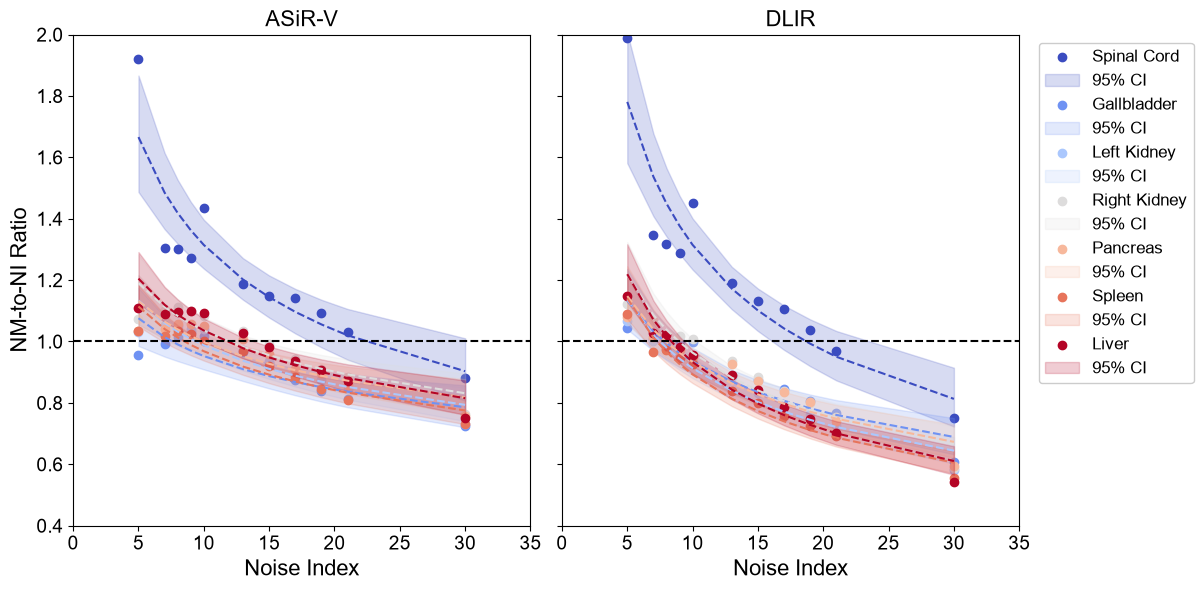

In [13]:
all_trend_vals = {}

fig,ax = plt.subplots(nrows=1, ncols=2, sharex=True, sharey=True, figsize=(12,6))

for r,recon_type in enumerate(all_noise_metrics.keys()):
    all_trend_vals[recon_type] = {}
    all_structs = [s for s in all_noise_metrics[recon_type].keys() if (('Vertebra' not in s) and ('Rib' not in s) and ('Lung' not in s) and ('Heart' not in s) and ('Stomach' not in s) and ('Hip' not in s) and ('Sacrum' not in s))]
    # Sort the structs by mean HU
    all_structs = [s[0] for s in sorted([(s,np.mean([all_noise_metrics['ASiR-V'][s]['HU'][ni]['mean'] for ni in all_noise_metrics['ASiR-V'][s]['HU'].keys()])) for s in all_structs], key=lambda s:s[1])]
    plot_colors = plt.colormaps['coolwarm'](np.linspace(0, 1, len(all_structs)))

    for struct_type in all_structs:
        temp_x_data = []
        temp_y_data = []
        for n,temp_NI in enumerate(all_noise_metrics[recon_type][struct_type]['calibration_factor'].keys()):
            if n == 0:
                ax[r].scatter(temp_NI, all_noise_metrics[recon_type][struct_type]['calibration_factor'][temp_NI], color=plot_colors[all_structs.index(struct_type)], label=struct_type)
            else:
                ax[r].scatter(temp_NI, all_noise_metrics[recon_type][struct_type]['calibration_factor'][temp_NI], color=plot_colors[all_structs.index(struct_type)])
            temp_x_data.append(temp_NI)
            temp_y_data.append(all_noise_metrics[recon_type][struct_type]['calibration_factor'][temp_NI])

        temp_x_data = np.array(temp_x_data).astype(np.float64)
        temp_y_data = np.array(temp_y_data).astype(np.float64)
        derived_y_data = all_fit_params[recon_type][struct_type]['a'][0] * ((temp_x_data)**(all_fit_params[recon_type][struct_type]['b'][0] - 1))
        ln_x = np.log(temp_x_data)
        ln_y = np.log(temp_y_data)
        ln_y_pred = (all_fit_params[recon_type][struct_type]['b'][0] - 1)*ln_x + np.log(all_fit_params[recon_type][struct_type]['a'][0])
        ss_res = np.sum((ln_y - ln_y_pred) ** 2)
        ss_tot = np.sum((ln_y - np.mean(ln_y)) ** 2)
        r_squared = 1 - (ss_res / ss_tot)
        print(f'{struct_type} / {recon_type}: y = {all_fit_params[recon_type][struct_type]['a'][0]:.2f}x^{(all_fit_params[recon_type][struct_type]['b'][0] - 1):.2f} (r2 = {r_squared:.2f})')
        ax[r].plot(temp_x_data, derived_y_data, linestyle='--', color=plot_colors[all_structs.index(struct_type)])
        # 95% CI
        n = len(temp_x_data)
        dof = n - 2
        se_residual = np.sqrt(ss_res / dof)
        t_critical = stats.t.ppf(0.975, df=dof)
        ss_x = np.sum((ln_x - np.mean(ln_x)) ** 2)
        se_fit = se_residual * np.sqrt(1/n + ((ln_x - np.mean(ln_x)) ** 2) / ss_x)
        ln_ci_upper = ln_y_pred + t_critical*se_fit
        ln_ci_lower = ln_y_pred - t_critical*se_fit
        y_ci_upper = np.exp(ln_ci_upper)
        y_ci_lower = np.exp(ln_ci_lower)
        ax[r].fill_between(temp_x_data, y_ci_lower, y_ci_upper, color=plot_colors[all_structs.index(struct_type)], alpha=0.2, label='95% CI')

        se_slope = se_residual / np.sqrt(ss_x)
        b_ci_lower = all_fit_params[recon_type][struct_type]['b'][0] - t_critical*se_slope
        b_ci_upper = all_fit_params[recon_type][struct_type]['b'][0] + t_critical*se_slope
        se_intercept = se_residual * np.sqrt(1/n + (np.mean(ln_x) ** 2) / ss_x)
        a_ci_lower = np.exp(np.log(all_fit_params[recon_type][struct_type]['a'][0]) - t_critical*se_intercept)
        a_ci_upper = np.exp(np.log(all_fit_params[recon_type][struct_type]['a'][0]) + t_critical*se_intercept)
        print(f'Parameter a: {all_fit_params[recon_type][struct_type]['a'][0]:.2f} (95% CI: {a_ci_lower:.2f} to {a_ci_upper:.2f})')
        print(f'Parameter b: {all_fit_params[recon_type][struct_type]['b'][0]:.2f} (95% CI: {b_ci_lower:.2f} to {b_ci_upper:.2f})')
        print()

    print()
    ax[r].plot([0,35], [1,1], linestyle='--', color='k')
    ax[r].tick_params(axis='x', labelsize=14)
    ax[r].tick_params(axis='y', labelsize=14)
    ax[r].set_xlim([0,35])
    ax[r].set_ylim([0.4,2])
    ax[r].set_xlabel('Noise Index', fontsize=16)
    ax[r].set_title(recon_type, fontsize=16)
ax[0].set_ylabel('NM-to-NI Ratio', fontsize=16)
plt.legend(bbox_to_anchor=(1.4,1), loc='upper right', framealpha=1, fontsize=12)
plt.tight_layout()
plt.show()


# NM-to-NI ratio of DLIR vs. ASiR-V

Spinal Cord: y = 1.18x + -0.24 (r2 = 0.99)
Spinal Cord: Intercept = 1.3
Fit Equation: y = (1.18 ± 0.08) * x + (-0.24 ± 0.10)
Slope 95% CI: [1.10, 1.26]
Y-Intercept 95% CI: [-0.34, -0.13]
X-Intercept 95% CI: [0.1, 0.3]

Gallbladder: y = 1.25x + -0.26 (r2 = 0.87)
Gallbladder: Intercept = 1.0
Fit Equation: y = (1.25 ± 0.36) * x + (-0.26 ± 0.33)
Slope 95% CI: [0.89, 1.61]
Y-Intercept 95% CI: [-0.60, 0.07]
X-Intercept 95% CI: [-0.1, 0.4]

Left Kidney: y = 1.31x + -0.38 (r2 = 0.93)
Left Kidney: Intercept = 1.2
Fit Equation: y = (1.31 ± 0.26) * x + (-0.38 ± 0.25)
Slope 95% CI: [1.04, 1.57]
Y-Intercept 95% CI: [-0.63, -0.13]
X-Intercept 95% CI: [0.1, 0.4]

Right Kidney: y = 1.36x + -0.45 (r2 = 0.93)
Right Kidney: Intercept = 1.2
Fit Equation: y = (1.36 ± 0.27) * x + (-0.45 ± 0.28)
Slope 95% CI: [1.09, 1.64]
Y-Intercept 95% CI: [-0.73, -0.17]
X-Intercept 95% CI: [0.2, 0.4]

Pancreas: y = 1.33x + -0.39 (r2 = 0.91)
Pancreas: Intercept = 1.2
Fit Equation: y = (1.33 ± 0.31) * x + (-0.39 ± 0.30)
Slo

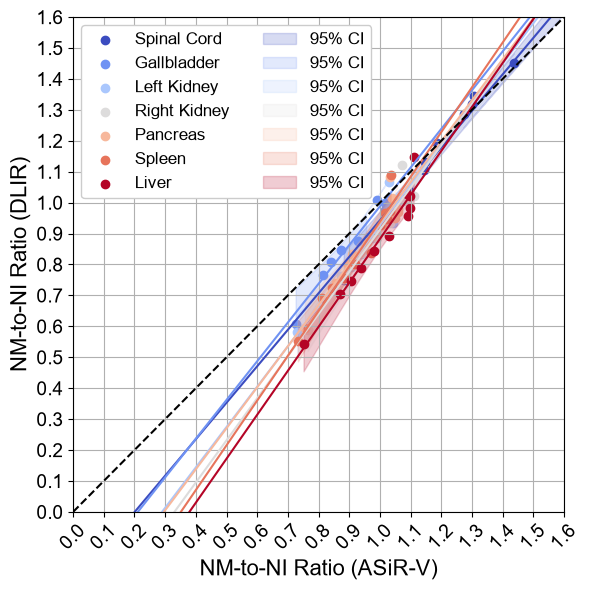

In [14]:
plt.figure(figsize=(6,6))

all_structs = [s for s in all_noise_metrics['ASiR-V'].keys() if (('Vertebra' not in s) and ('Rib' not in s) and ('Lung' not in s) and ('Heart' not in s) and ('Stomach' not in s) and ('Hip' not in s) and ('Sacrum' not in s))]
# Sort the structs by mean HU
all_structs = [s[0] for s in sorted([(s,np.mean([all_noise_metrics['ASiR-V'][s]['HU'][ni]['mean'] for ni in all_noise_metrics['ASiR-V'][s]['HU'].keys()])) for s in all_structs], key=lambda s:s[1])]
plot_colors = plt.colormaps['coolwarm'](np.linspace(0, 1, len(all_structs)))

for struct_type in all_structs:
    temp_x_data = []
    temp_y_data = []
    for n,temp_NI in enumerate(all_noise_metrics['ASiR-V'][struct_type]['calibration_factor'].keys()):
        if n == 0:
            plt.scatter(all_noise_metrics['ASiR-V'][struct_type]['calibration_factor'][temp_NI], all_noise_metrics['DLIR'][struct_type]['calibration_factor'][temp_NI], color=plot_colors[all_structs.index(struct_type)], label=struct_type)
        else:
            plt.scatter(all_noise_metrics['ASiR-V'][struct_type]['calibration_factor'][temp_NI], all_noise_metrics['DLIR'][struct_type]['calibration_factor'][temp_NI], color=plot_colors[all_structs.index(struct_type)])
        temp_x_data.append(all_noise_metrics['ASiR-V'][struct_type]['calibration_factor'][temp_NI])
        temp_y_data.append(all_noise_metrics['DLIR'][struct_type]['calibration_factor'][temp_NI])

    temp_x_data = np.array(temp_x_data).astype(np.float64)
    temp_y_data = np.array(temp_y_data).astype(np.float64)
    popt, pcov = curve_fit(linear_slope, temp_x_data, temp_y_data, p0=[1,0])
    y_pred = linear_slope(temp_x_data, *popt)
    ss_res = np.sum((temp_y_data - y_pred) ** 2)
    ss_tot = np.sum((temp_y_data - np.mean(temp_y_data)) ** 2)
    r_squared = 1 - (ss_res / ss_tot)
    print(f'{struct_type}: y = {popt[0]:.2f}x + {popt[1]:.2f} (r2 = {r_squared:.2f})')
    plot_x_data = np.arange(0,1.7,0.1)
    plt.plot(plot_x_data, linear_slope(plot_x_data, *popt), linestyle='-', color=plot_colors[all_structs.index(struct_type)])
    print(f'{struct_type}: Intercept = {-(popt[1]/(popt[0]-1)):.1f}')
    # 95% CI
    n = len(temp_x_data)
    dof = max(0, n-2)
    t_val = t.ppf(0.975, dof)
    perr = np.sqrt(np.diag(pcov))
    m_ci = t_val * perr[0]
    b_ci = t_val * perr[1]
    s_err = np.sqrt(np.sum((temp_y_data - y_pred)**2) / dof)
    s_fit = s_err * np.sqrt(1 / n + (temp_x_data - np.mean(temp_x_data))**2 / np.sum((temp_x_data - np.mean(temp_x_data))**2))
    y_ci_lower = y_pred - t_val*s_fit
    y_ci_upper = y_pred + t_val*s_fit
    plt.fill_between(temp_x_data, y_ci_lower, y_ci_upper, color=plot_colors[all_structs.index(struct_type)], alpha=0.2, label='95% CI')
    print(f'Fit Equation: y = ({popt[0]:.2f} ± {m_ci:.2f}) * x + ({popt[1]:.2f} ± {b_ci:.2f})')
    print(f'Slope 95% CI: [{popt[0] - m_ci:.2f}, {popt[0] + m_ci:.2f}]')
    print(f'Y-Intercept 95% CI: [{popt[1] - b_ci:.2f}, {popt[1] + b_ci:.2f}]')
    x_ci_lower = -((popt[1] + b_ci) / (popt[0] - m_ci))
    x_ci_upper = -((popt[1] - b_ci) / (popt[0] + m_ci))
    print(f'X-Intercept 95% CI: [{x_ci_lower:.1f}, {x_ci_upper:.1f}]')
    print()

plt.plot([0,1.6], [0,1.6], linestyle='--', color='k')
plt.tick_params(axis='x', labelsize=14)
plt.tick_params(axis='y', labelsize=14)
plt.xlim([0,1.6])
plt.ylim([0,1.6])
plt.xlabel('NM-to-NI Ratio (ASiR-V)', fontsize=16)
plt.ylabel('NM-to-NI Ratio (DLIR)', fontsize=16)
ax = plt.gca()
ax.set_xticks(np.arange(0,1.7,0.1))
ax.set_yticks(np.arange(0,1.7,0.1))
ax.set_xticklabels([round(n,1) for n in  np.arange(0,1.7,0.1)], rotation=45)
handles,labels = ax.get_legend_handles_labels()
reordered_handles = sum([handles[i::2] for _,i in enumerate(range(2))], [])
reordered_labels = sum([labels[i::2] for _,i in enumerate(range(2))], [])
ax.legend(reordered_handles, reordered_labels, loc='upper left', ncols=2, framealpha=1, fontsize=12)
plt.grid()
plt.tight_layout()
plt.show()


# Plot the Noise Reduction Ratio (NRR)

Spinal Cord: y = 0.72x + -8.18 (r2 = 0.97)
Fit Equation: y = (0.72 ± 0.10) * x + (-8.18 ± 1.57)
Slope 95% CI: [0.61, 0.82]
Y-Intercept 95% CI: [-9.76, -6.61]
X-Intercept 95% CI: [10.8, 12.0]

Gallbladder: y = 0.69x + -5.96 (r2 = 0.67)
Fit Equation: y = (0.69 ± 0.37) * x + (-5.96 ± 5.76)
Slope 95% CI: [0.33, 1.06]
Y-Intercept 95% CI: [-11.72, -0.19]
X-Intercept 95% CI: [0.6, 11.0]

Left Kidney: y = 0.74x + -0.73 (r2 = 0.82)
Fit Equation: y = (0.74 ± 0.26) * x + (-0.73 ± 4.15)
Slope 95% CI: [0.48, 1.01]
Y-Intercept 95% CI: [-4.88, 3.42]
X-Intercept 95% CI: [-7.2, 4.8]

Right Kidney: y = 0.87x + -2.84 (r2 = 0.86)
Fit Equation: y = (0.87 ± 0.26) * x + (-2.84 ± 4.11)
Slope 95% CI: [0.61, 1.13]
Y-Intercept 95% CI: [-6.95, 1.26]
X-Intercept 95% CI: [-2.1, 6.1]

Pancreas: y = 0.76x + -2.07 (r2 = 0.78)
Fit Equation: y = (0.76 ± 0.30) * x + (-2.07 ± 4.77)
Slope 95% CI: [0.45, 1.06]
Y-Intercept 95% CI: [-6.83, 2.70]
X-Intercept 95% CI: [-6.0, 6.4]

Spleen: y = 0.94x + -2.79 (r2 = 0.85)
Fit Equati

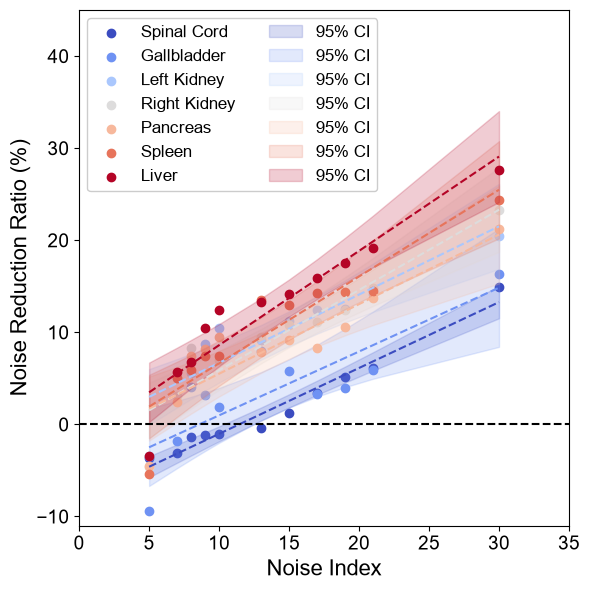

In [15]:
fit_vals = {}
def linear_slope(x, m, b):
    return m*x + b

plt.figure(figsize=(6,6))
ax = plt.gca()
ax.tick_params(axis='x', labelsize=14)
ax.tick_params(axis='y', labelsize=14)

all_structs = [s for s in all_noise_metrics[recon_type].keys() if (('Vertebra' not in s) and ('Rib' not in s) and ('Lung' not in s) and ('Heart' not in s) and ('Stomach' not in s) and ('Hip' not in s) and ('Sacrum' not in s))]
# Sort the structs by mean HU
all_structs = [s[0] for s in sorted([(s,np.mean([all_noise_metrics['ASiR-V'][s]['HU'][ni]['mean'] for ni in all_noise_metrics['ASiR-V'][s]['HU'].keys()])) for s in all_structs], key=lambda s:s[1])]
plot_colors = plt.colormaps['coolwarm'](np.linspace(0, 1, len(all_structs)))

organ_vals = {
    'Spinal Cord': {
        'volume': 43,
        'HU (ASiR-V)': 8,
        'HU (DLIR)': 8
    },
    'Gallbladder': {
        'volume': 15,
        'HU (ASiR-V)': 18,
        'HU (DLIR)': 18
    },
    'Left Kidney': {
        'volume': 88,
        'HU (ASiR-V)': 26,
        'HU (DLIR)': 26
    },
    'Right Kidney': {
        'volume': 88,
        'HU (ASiR-V)': 26,
        'HU (DLIR)': 26
    },
    'Pancreas': {
        'volume': 41,
        'HU (ASiR-V)': 26,
        'HU (DLIR)': 27
    },
    'Spleen': {
        'volume': 141,
        'HU (ASiR-V)': 49,
        'HU (DLIR)': 50
    },
    'Liver': {
        'volume': 1086,
        'HU (ASiR-V)': 68,
        'HU (DLIR)': 68
    },
}
for struct_type in all_structs:
    temp_x_data = []
    temp_y_data = []
    for n,temp_NI in enumerate(all_noise_metrics[recon_type][struct_type]['noise_metric'].keys()):
        if n == 0:
            plt.scatter(
                temp_NI,
                100 * (all_noise_metrics['ASiR-V'][struct_type]['noise_metric'][temp_NI] - all_noise_metrics['DLIR'][struct_type]['noise_metric'][temp_NI]) / all_noise_metrics['ASiR-V'][struct_type]['noise_metric'][temp_NI],
                color=plot_colors[all_structs.index(struct_type)], label=struct_type
            )
        else:
            plt.scatter(
                temp_NI,
                100 * (all_noise_metrics['ASiR-V'][struct_type]['noise_metric'][temp_NI] - all_noise_metrics['DLIR'][struct_type]['noise_metric'][temp_NI]) / all_noise_metrics['ASiR-V'][struct_type]['noise_metric'][temp_NI],
                color=plot_colors[all_structs.index(struct_type)]
            )
        temp_x_data.append(temp_NI)
        temp_y_data.append(100 * (all_noise_metrics['ASiR-V'][struct_type]['noise_metric'][temp_NI] - all_noise_metrics['DLIR'][struct_type]['noise_metric'][temp_NI]) / all_noise_metrics['ASiR-V'][struct_type]['noise_metric'][temp_NI])
    temp_x_data = np.array(temp_x_data).astype(np.float64)
    temp_y_data = np.array(temp_y_data).astype(np.float64)
    popt, pcov = curve_fit(linear_slope, temp_x_data, temp_y_data, p0=[1,0])
    y_pred = linear_slope(temp_x_data, *popt)
    ss_res = np.sum((temp_y_data - y_pred)**2)
    ss_tot = np.sum((temp_y_data - np.mean(temp_y_data))**2)
    r_squared = 1 - (ss_res / ss_tot)
    print(f'{struct_type}: y = {popt[0]:.2f}x + {popt[1]:.2f} (r2 = {r_squared:.2f})')
    plt.plot(temp_x_data, linear_slope(temp_x_data, *popt), linestyle='--', color=plot_colors[all_structs.index(struct_type)])
    # 95% CI
    n = len(temp_x_data)
    p = len(popt)
    dof = max(0, n-p)
    t_val = t.ppf(0.975, dof)
    perr = np.sqrt(np.diag(pcov))
    m_ci = t_val * perr[0]
    b_ci = t_val * perr[1]
    s_err = np.sqrt(np.sum((temp_y_data - y_pred)**2) / dof)
    s_fit = s_err * np.sqrt(1 / n + (temp_x_data - np.mean(temp_x_data))**2 / np.sum((temp_x_data - np.mean(temp_x_data))**2))
    y_ci_lower = y_pred - t_val*s_fit
    y_ci_upper = y_pred + t_val*s_fit
    plt.fill_between(temp_x_data, y_ci_lower, y_ci_upper, color=plot_colors[all_structs.index(struct_type)], alpha=0.2, label='95% CI')
    print(f'Fit Equation: y = ({popt[0]:.2f} ± {m_ci:.2f}) * x + ({popt[1]:.2f} ± {b_ci:.2f})')
    print(f'Slope 95% CI: [{popt[0] - m_ci:.2f}, {popt[0] + m_ci:.2f}]')
    print(f'Y-Intercept 95% CI: [{popt[1] - b_ci:.2f}, {popt[1] + b_ci:.2f}]')
    x_ci_lower = -((popt[1] + b_ci) / (popt[0] - m_ci))
    x_ci_upper = -((popt[1] - b_ci) / (popt[0] + m_ci))
    print(f'X-Intercept 95% CI: [{x_ci_lower:.1f}, {x_ci_upper:.1f}]')
    print()
    fit_vals[struct_type] = {
        'volume': organ_vals[struct_type]['volume'],
        'HU': np.mean([organ_vals[struct_type]['HU (ASiR-V)'], organ_vals[struct_type]['HU (DLIR)']]),
        'slope': popt[0],
        'intercept': popt[1]
    }

plt.plot([0,35], [0,0], linestyle='--', color='k')
plt.xlim([0,35])
plt.ylim([-11,45])
plt.xlabel('Noise Index', fontsize=16)
plt.ylabel('Noise Reduction Ratio (%)', fontsize=16)
ax = plt.gca()
handles,labels = ax.get_legend_handles_labels()
reordered_handles = sum([handles[i::2] for _,i in enumerate(range(2))], [])
reordered_labels = sum([labels[i::2] for _,i in enumerate(range(2))], [])
ax.legend(reordered_handles, reordered_labels, loc='upper left', ncols=2, framealpha=1, fontsize=12)
plt.tight_layout()
plt.show()
